# TERZ net comparison: embeddings + density + clustering

For every (year, `ont`) combination this notebook:

1. loads the TERZ parquet, normalises each trigger by its max and standardises the features (same preprocessing as `net_compare_cut.ipynb`),
2. computes a t-SNE and a UMAP embedding (cached on disk, so the slow part only runs once),
3. draws **one 2x2 figure per projection**: embedding scatter, KDE density, k-means (centroids at the KDE peaks), HDBSCAN (the logic of `density.ipynb`),
4. (last section) draws `PER_CLUSTER` random triggers from every k-means cluster and computes t-SNE and UMAP again on that balanced subset, coloured by the first-round k-means label.

Half-width window is 12 s (`hw12`), as in `net_compare_cut.ipynb`.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter
from scipy.stats import gaussian_kde
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances_argmin
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
METRIC = "euclidean"

PARQUET_DIR = Path("year_TERZ_parquets")
CACHE_DIR = Path("TERZ_embeddings_cache")      # embeddings are stored here
CACHE_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("TERZ_figures_net_compare_sampling")
SAVE_FIGS = True                         # True -> also save every figure as a PNG in FIG_DIR

# What to run. net_compare_cut.ipynb only processed 2022; add the other years here.
YEARS = [2022]                            # e.g. [2022, 2023, 2024, 2025]
ONTS = [15, 20, 25]
HW = [1, 2, 4, 6, 12]                       

# t-SNE (same values as net_compare_cut.ipynb)
PERPLEXITY = 350
EARLY_EXAGGERATION = 14

# UMAP -- placeholders, set these to the values you used in mn-sena-splited.ipynb
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1

# Clustering parameters (see the note below the cell)
#   kde_peak_size:       a KDE grid point is a peak if it is the maximum of its size x size window (grid cells)
#   kde_peak_min_rel:    peaks lower than this fraction of the tallest peak are ignored
#   hdbscan_min_samples: carried over from density.ipynb
CLUSTER_PARAMS = {
    "tsne": {"kde_peak_size": 15, "kde_peak_min_rel": 0.05, "hdbscan_min_samples": 500},
    "umap": {"kde_peak_size": 15, "kde_peak_min_rel": 0.05, "hdbscan_min_samples": 500},
}
# Per-dataset overrides, keyed by (year, ont, projection), e.g.
# CLUSTER_OVERRIDES = {(2022, 15, "umap"): {"kde_peak_min_rel": 0.1}}
CLUSTER_OVERRIDES = {}

# k-means: one cluster per KDE peak, the peaks are the centroids.
# False -> centroids stay exactly on the KDE peaks; every point goes to its nearest peak.
# True  -> the peaks are only the starting centroids; k-means (Lloyd iterations) then moves them.
KMEANS_REFINE = False

# Density panel
DENSITY_3D = True                         # True: 3D surface as in density.ipynb, False: 2D filled contours
GRID_SIZE = 200                           # density.ipynb used 500; 200 is ~6x faster to evaluate

PROJECTIONS = {"tsne": "t-SNE", "umap": "UMAP"}

# Balanced subset + second round of dimensionality reduction
LABEL_FROM = "tsne"                       # projection whose k-means clusters are the labels: "tsne" or "umap"
PER_CLUSTER = 1000                        # triggers drawn at random from every k-means cluster
SUBSET_DIR = Path("TERZ_subsets")         # selected row indices + labels are stored here
SUBSET_DIR.mkdir(exist_ok=True)
# embedding parameters for the subset (start from the values used on the full sets)
SUB_PERPLEXITY = 100 #PERPLEXITY
SUB_EARLY_EXAGGERATION = EARLY_EXAGGERATION
SUB_UMAP_N_NEIGHBORS = UMAP_N_NEIGHBORS
SUB_UMAP_MIN_DIST = UMAP_MIN_DIST

**Clustering parameters.** The k-means panel takes both the number of clusters and the centroids from the peaks of the Gaussian KDE: a peak is a grid point that is the maximum of its `kde_peak_size` x `kde_peak_size` neighbourhood and is at least `kde_peak_min_rel` times as high as the tallest peak. Too many peaks: raise either value; too few: lower them (use `CLUSTER_OVERRIDES` per dataset). With `KMEANS_REFINE = False` the centroids stay on the peaks; with `True` they are only the starting point of k-means.

`hdbscan_min_samples` comes from `density.ipynb`, where it was tuned for the MN-SENA embeddings. t-SNE/UMAP coordinates change scale with the perplexity, the number of points and the data, so for these TERZ sets it will probably need adjusting. `min_samples=500` is also a large fraction of the smaller sets (the 2025 `ont=25` set has about 10k triggers).

In [6]:
def feature_matrix(year, ont, hw, rows=None):
    """Load one parquet, normalise each row by its max and standardise (as in net_compare_cut.ipynb).
    If `rows` is given only those rows are kept, and the standardisation is fitted on them."""
    path = PARQUET_DIR / f"TERZ_HHZ_hw{hw}_ont{ont}_{year}.parquet"
    df = pd.read_parquet(path)

    feature_columns = [col for col in df.columns if col.startswith("feature_")]
    if len(feature_columns) == 0:
        raise ValueError(f"No feature_* columns found in {path}.")

    X = df[feature_columns].to_numpy(dtype="float64")
    if rows is not None:
        X = X[rows]
    print(f"{year} ont={ont}: {X.shape[0]} triggers, {X.shape[1]} features")

    X_norm = X / X.max(axis=1, keepdims=True)
    return StandardScaler().fit_transform(X_norm)


def compute_tsne(X_scaled):
    return TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE,
                metric=METRIC).fit_transform(X_scaled)


def compute_umap(X_scaled):
    import umap  # imported here so cached embeddings can be plotted without umap-learn
    return umap.UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                     metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_scaled)


COMPUTE = {"tsne": compute_tsne, "umap": compute_umap}


def cache_path(year, ont, projection, hw):
    # the parameters are part of the file name, so changing them never reuses a stale embedding
    if projection == "tsne":
        tag = f"tsne_perp{PERPLEXITY}_ee{EARLY_EXAGGERATION}"
    else:
        tag = f"umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}"
    return CACHE_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_{tag}.npy"


def get_embeddings(year, ont, hw):
    """Return {"tsne": (n, 2), "umap": (n, 2)}; computes and caches whatever is missing."""
    paths = {proj: cache_path(year, ont, proj, hw) for proj in COMPUTE}
    X_scaled = feature_matrix(year, ont, hw) if not all(p.exists() for p in paths.values()) else None

    embeddings = {}
    for proj, path in paths.items():
        if path.exists():
            embeddings[proj] = np.load(path)
            print(f"{year} ont={ont}: {PROJECTIONS[proj]} loaded from {path.name}")
        else:
            print(f"{year} ont={ont}: computing {PROJECTIONS[proj]} ...")
            embeddings[proj] = COMPUTE[proj](X_scaled)
            np.save(path, embeddings[proj])
    return embeddings

In [7]:
def density_surface(E, grid=None):
    """Gaussian KDE of the 2D embedding evaluated on a regular grid."""
    grid = grid or GRID_SIZE
    x, y = E[:, 0], E[:, 1]
    kde = gaussian_kde(np.vstack([x, y]))
    X, Y = np.meshgrid(np.linspace(x.min(), x.max(), grid), np.linspace(y.min(), y.max(), grid))
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    return X, Y, Z


def kde_peaks(X, Y, Z, size, min_rel):
    """Local maxima of the KDE surface on the grid, tallest first -> ((k, 2) positions, (k,) heights)."""
    is_peak = (Z == maximum_filter(Z, size=size)) & (Z >= min_rel * Z.max())
    rows, cols = np.nonzero(is_peak)
    order = np.argsort(Z[rows, cols])[::-1]
    rows, cols = rows[order], cols[order]
    return np.column_stack([X[rows, cols], Y[rows, cols]]), Z[rows, cols]


def kmeans_labels(E, peaks):
    """k-means with one cluster per KDE peak. The peaks are the centroids (the initial ones if KMEANS_REFINE)."""
    if KMEANS_REFINE:
        km = KMeans(n_clusters=len(peaks), init=peaks, n_init=1, random_state=RANDOM_STATE).fit(E)
        return km.labels_, km.cluster_centers_
    return pairwise_distances_argmin(E, peaks), peaks


def cluster_labels(E, params, X, Y, Z):
    peaks, _ = kde_peaks(X, Y, Z, params["kde_peak_size"], params["kde_peak_min_rel"])
    km_labels, centroids = kmeans_labels(E, peaks)
    hdbscan = HDBSCAN(min_samples=params["hdbscan_min_samples"], metric=METRIC, copy=True).fit(E)
    return km_labels, centroids, hdbscan.labels_


def plot_clusters(ax, E, labels, title, xlabel, ylabel):
    noise = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    ax.scatter(E[noise, 0], E[noise, 1], c="lightgray", s=8, alpha=0.5, label="noise")
    ax.scatter(E[~noise, 0], E[~noise, 1], c=labels[~noise], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"{title}\n{n_clusters} clusters, {noise.sum()} noise points")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if noise.any():
        ax.legend(loc="best", markerscale=2)
    return n_clusters, int(noise.sum())


def plot_kmeans(ax, E, labels, centroids, title, xlabel, ylabel):
    ax.scatter(E[:, 0], E[:, 1], c=labels, cmap="viridis", s=8, alpha=0.7)
    ax.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=150, c="red",
               edgecolors="black", linewidths=1, label="centroids")
    ax.set_title(f"{title}\n{len(centroids)} clusters")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best")
    return len(centroids)


def plot_projection(E, proj, year, ont):
    """One figure: embedding | density | k-means | HDBSCAN."""
    name = PROJECTIONS[proj]
    params = {**CLUSTER_PARAMS[proj], **CLUSTER_OVERRIDES.get((year, ont, proj), {})}
    xlabel, ylabel = f"{name} 1", f"{name} 2"

    X, Y, Z = density_surface(E)
    km_labels, centroids, hdb_labels = cluster_labels(E, params, X, Y, Z)

    fig = plt.figure(figsize=(16, 13))

    # 1) embedding
    ax = fig.add_subplot(2, 2, 1)
    ax.scatter(E[:, 0], E[:, 1], s=5, alpha=0.5)
    if proj == "tsne":
        ax.set_title(f"{name} | hw = {hw} | Perplexity = {PERPLEXITY} | Early Exaggeration = {EARLY_EXAGGERATION} | Metric = {METRIC}")
    else:
        ax.set_title(f"{name} | hw = {hw} | n_neighbors = {UMAP_N_NEIGHBORS} | min_dist = {UMAP_MIN_DIST} | Metric = {METRIC}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 2) density
    if DENSITY_3D:
        ax = fig.add_subplot(2, 2, 2, projection="3d")
        surf = ax.plot_surface(X, Y, Z, cmap="coolwarm", linewidth=0, antialiased=False)
        ax.set_zlabel("density")
    else:
        ax = fig.add_subplot(2, 2, 2)
        surf = ax.contourf(X, Y, Z, levels=30, cmap="coolwarm")
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.1)
    ax.set_title(f"Gaussian KDE density on the {name} embedding")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 3) k-means, centroids at the KDE peaks
    ax = fig.add_subplot(2, 2, 3)
    mode = "peaks as initial centroids" if KMEANS_REFINE else "centroids fixed at KDE peaks"
    n_km = plot_kmeans(ax, E, km_labels, centroids, f"k-means ({mode})", xlabel, ylabel)

    # 4) HDBSCAN
    ax = fig.add_subplot(2, 2, 4)
    n_hdb, noise_hdb = plot_clusters(
        ax, E, hdb_labels,
        f"HDBSCAN (min_samples={params['hdbscan_min_samples']})",
        xlabel, ylabel)

    fig.suptitle(f"{year} | ont={ont} | {name} | {E.shape[0]} triggers", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_{proj}.png", dpi=150)
    plt.show()
    plt.close(fig)

    print(f"{year} ont={ont} {name}: k-means {n_km} clusters, "
          f"HDBSCAN {n_hdb} clusters / {noise_hdb} noise")


def run(year, ont, hw):
    embeddings = get_embeddings(year, ont, hw)
    for proj in PROJECTIONS:
        plot_projection(embeddings[proj], proj, year, ont)

## Run

Loops over `YEARS` x `ONTS`. To look at a single case, call e.g. `run(2022, 20)` instead.

2022 ont=15: t-SNE loaded from TERZ_hw1_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw1_ont15_2022_umap_nn15_md0.1.npy


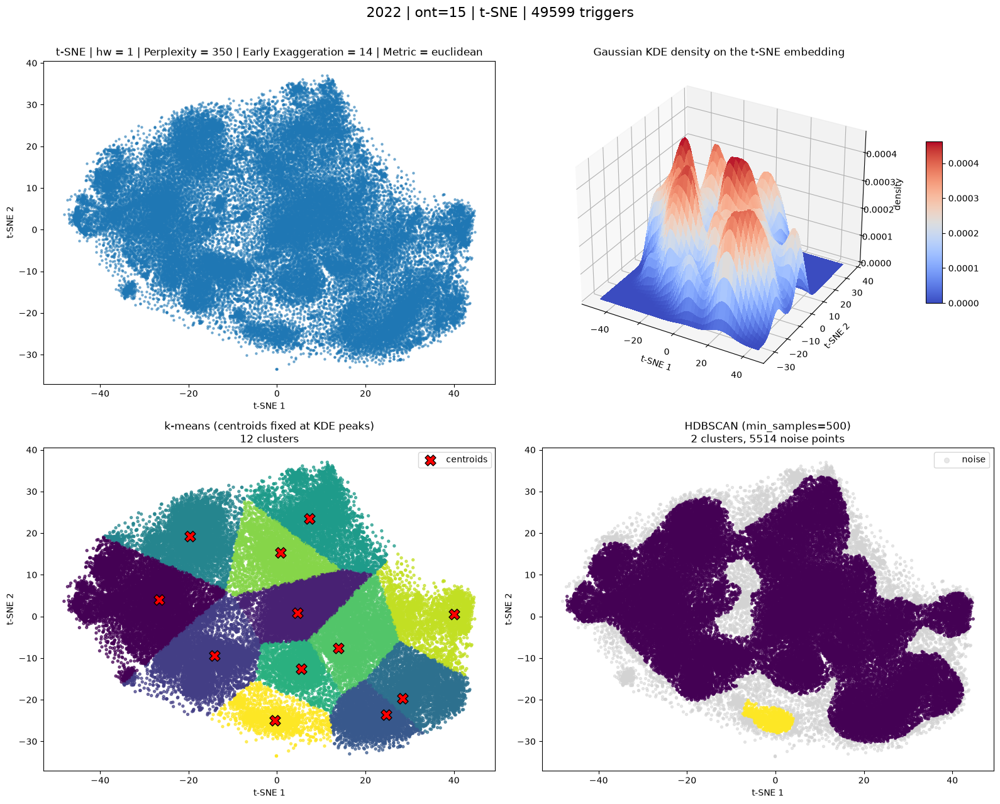

2022 ont=15 t-SNE: k-means 12 clusters, HDBSCAN 2 clusters / 5514 noise


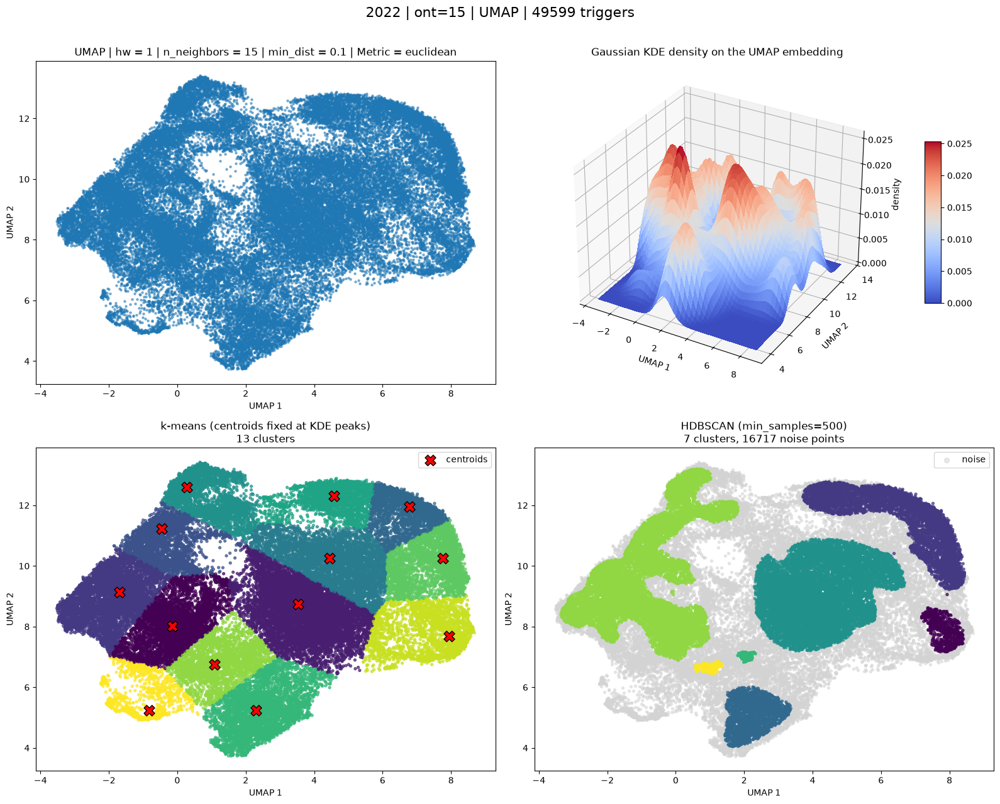

2022 ont=15 UMAP: k-means 13 clusters, HDBSCAN 7 clusters / 16717 noise
2022 ont=15: t-SNE loaded from TERZ_hw2_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw2_ont15_2022_umap_nn15_md0.1.npy


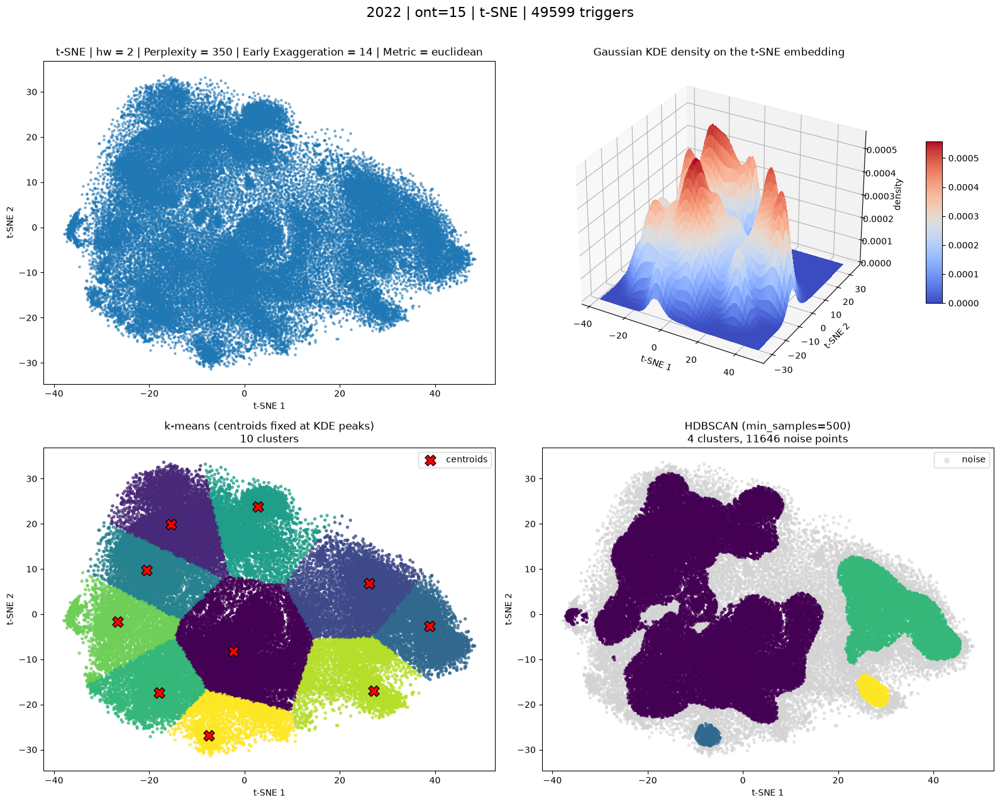

2022 ont=15 t-SNE: k-means 10 clusters, HDBSCAN 4 clusters / 11646 noise


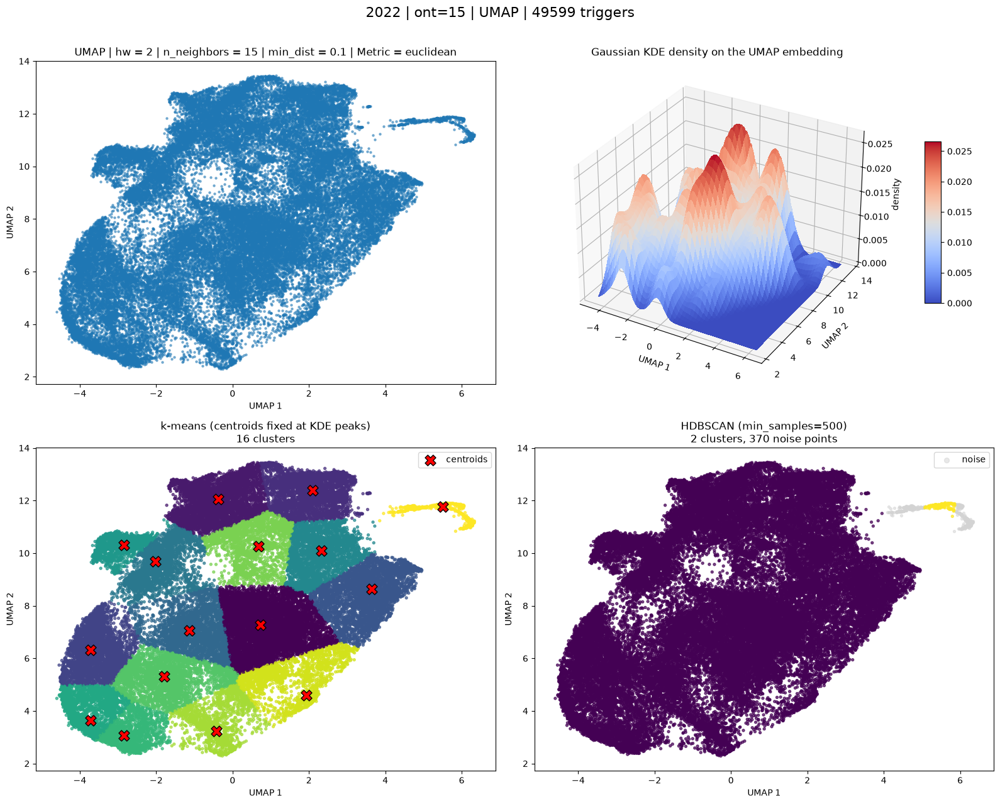

2022 ont=15 UMAP: k-means 16 clusters, HDBSCAN 2 clusters / 370 noise
2022 ont=15: t-SNE loaded from TERZ_hw4_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw4_ont15_2022_umap_nn15_md0.1.npy


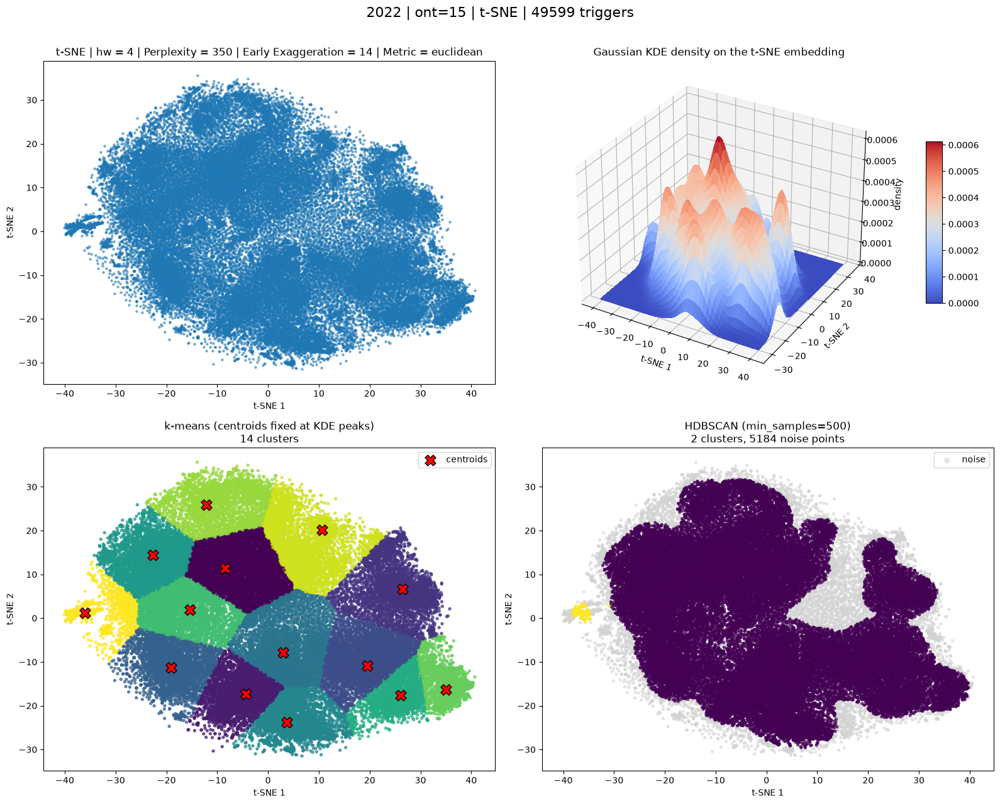

2022 ont=15 t-SNE: k-means 14 clusters, HDBSCAN 2 clusters / 5184 noise


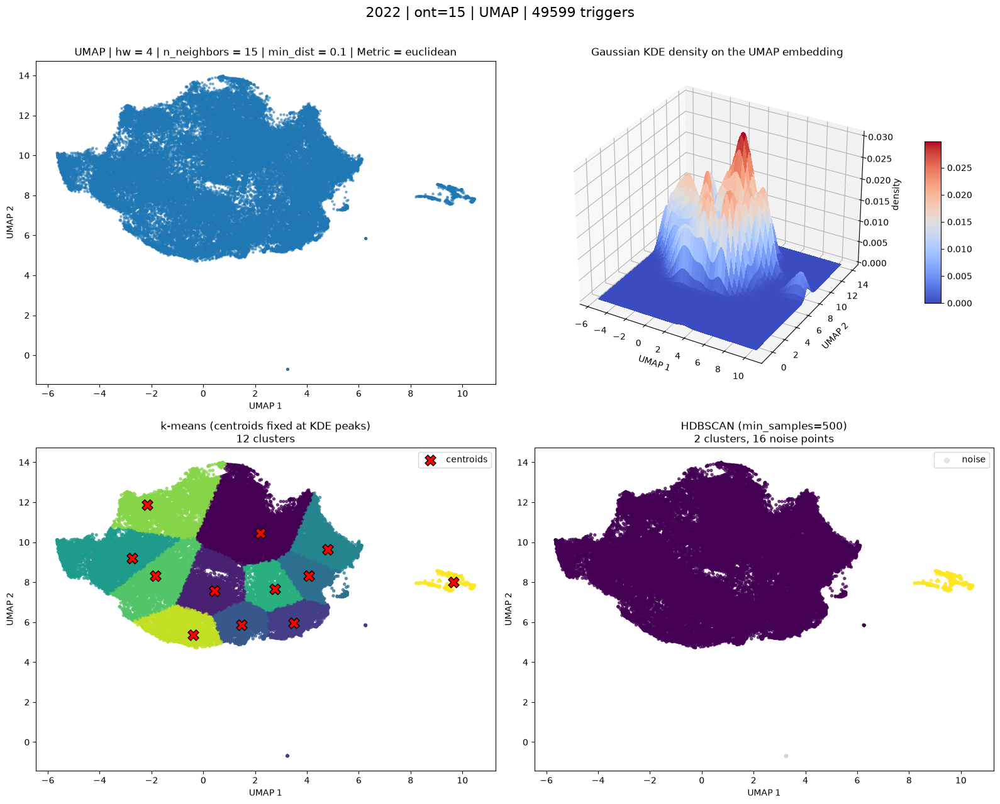

2022 ont=15 UMAP: k-means 12 clusters, HDBSCAN 2 clusters / 16 noise
2022 ont=15: t-SNE loaded from TERZ_hw6_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw6_ont15_2022_umap_nn15_md0.1.npy


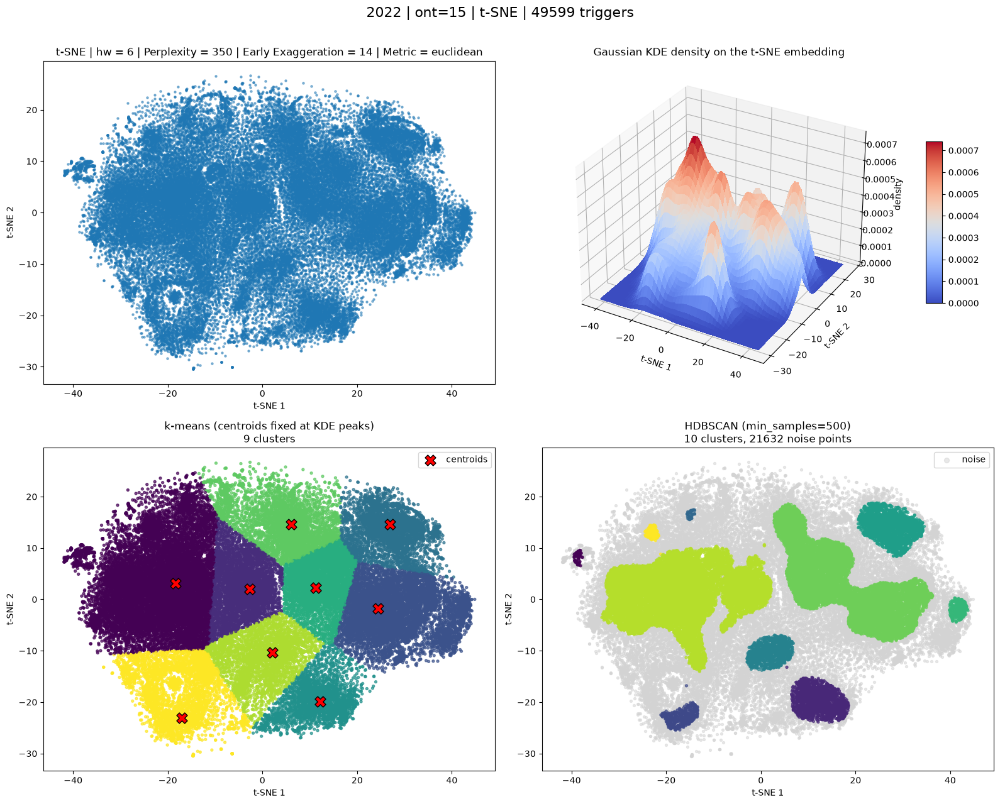

2022 ont=15 t-SNE: k-means 9 clusters, HDBSCAN 10 clusters / 21632 noise


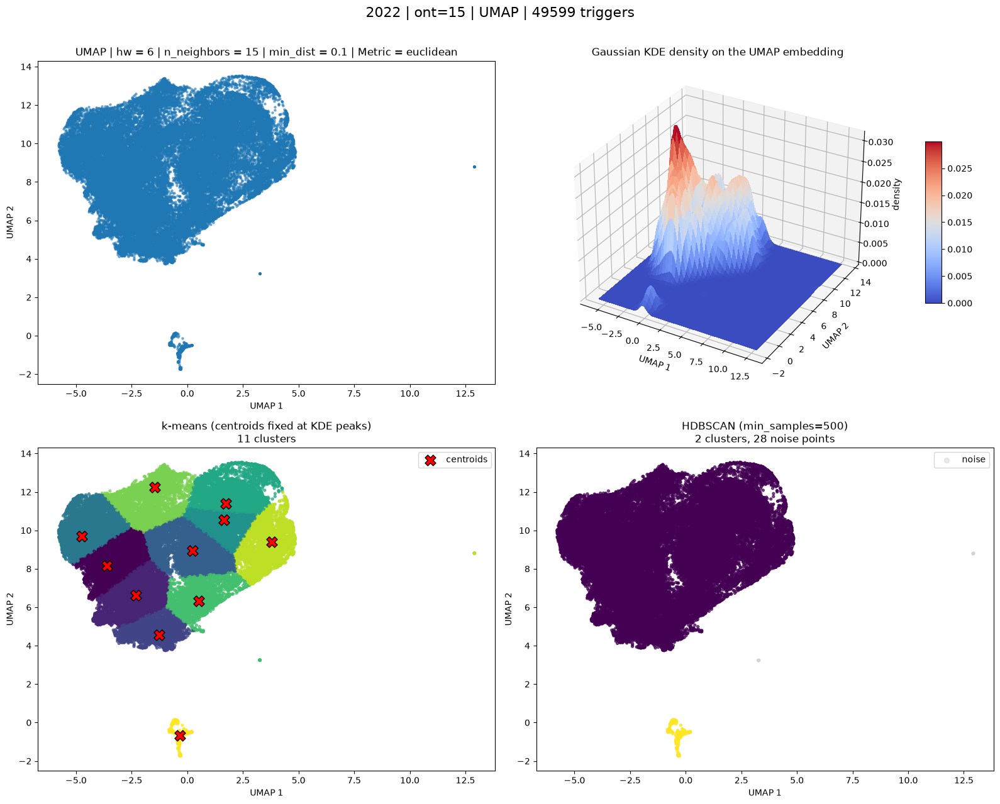

2022 ont=15 UMAP: k-means 11 clusters, HDBSCAN 2 clusters / 28 noise
2022 ont=15: t-SNE loaded from TERZ_hw12_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw12_ont15_2022_umap_nn15_md0.1.npy


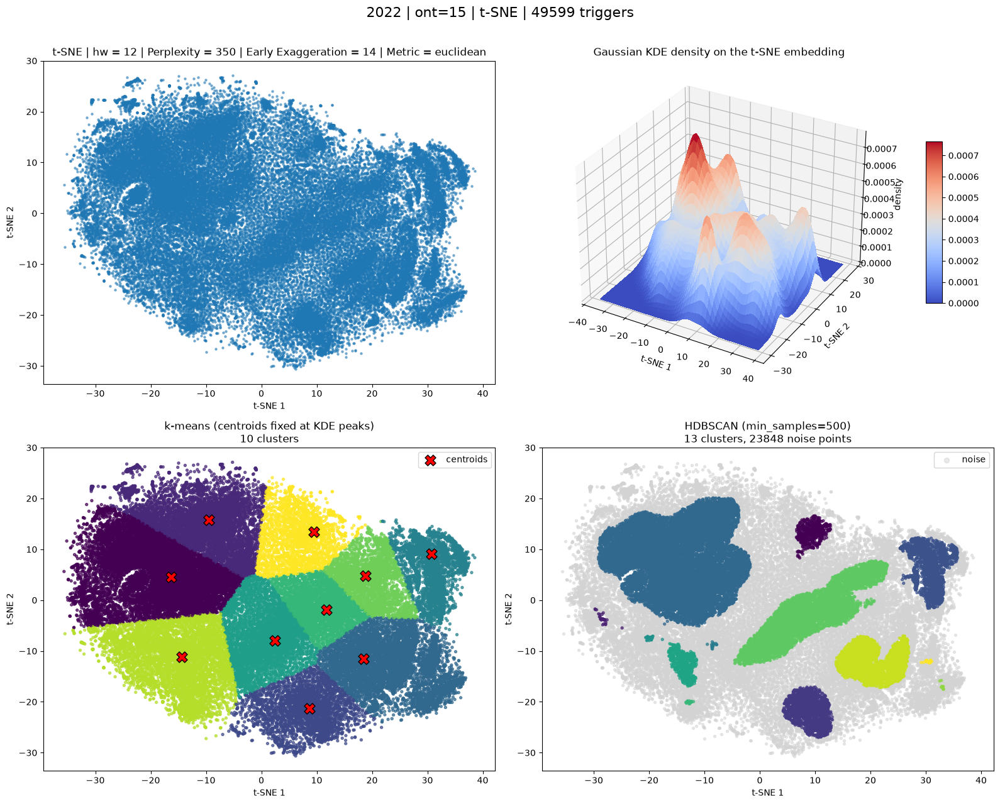

2022 ont=15 t-SNE: k-means 10 clusters, HDBSCAN 13 clusters / 23848 noise


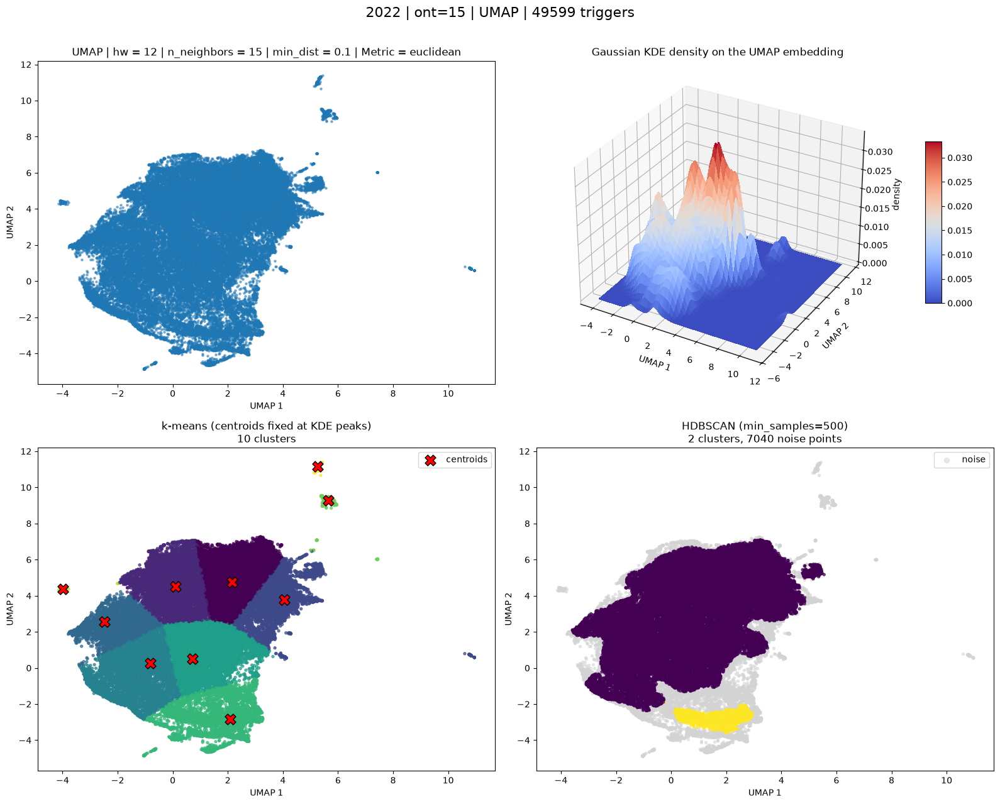

2022 ont=15 UMAP: k-means 10 clusters, HDBSCAN 2 clusters / 7040 noise
2022 ont=20: t-SNE loaded from TERZ_hw1_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw1_ont20_2022_umap_nn15_md0.1.npy


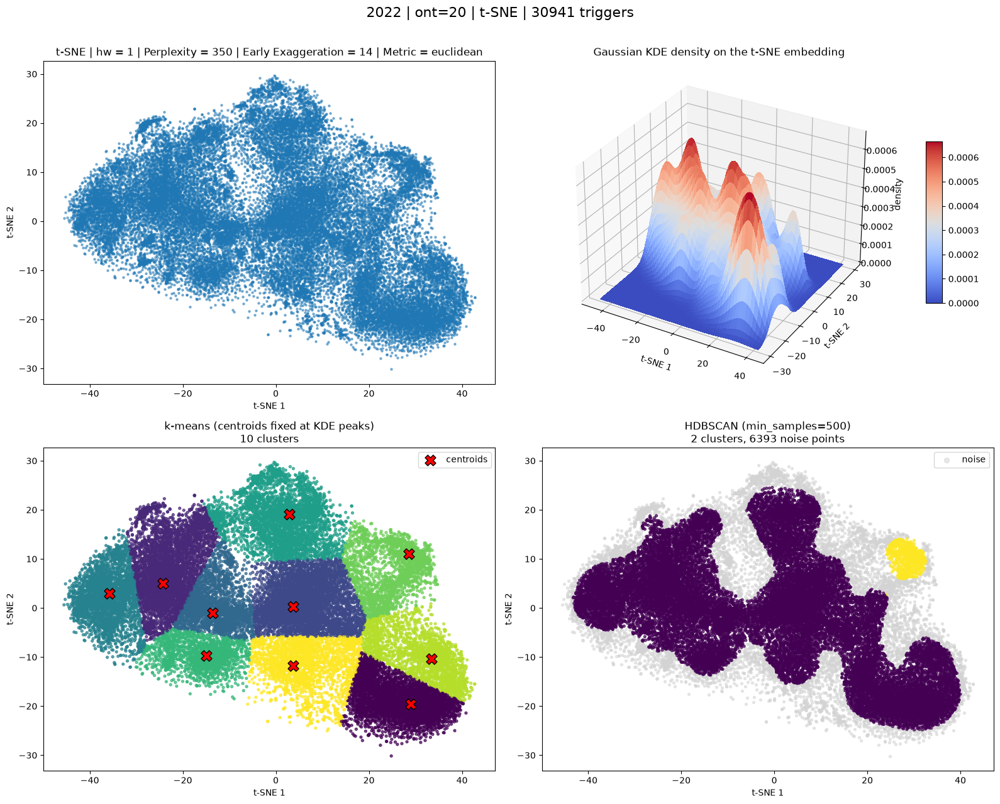

2022 ont=20 t-SNE: k-means 10 clusters, HDBSCAN 2 clusters / 6393 noise


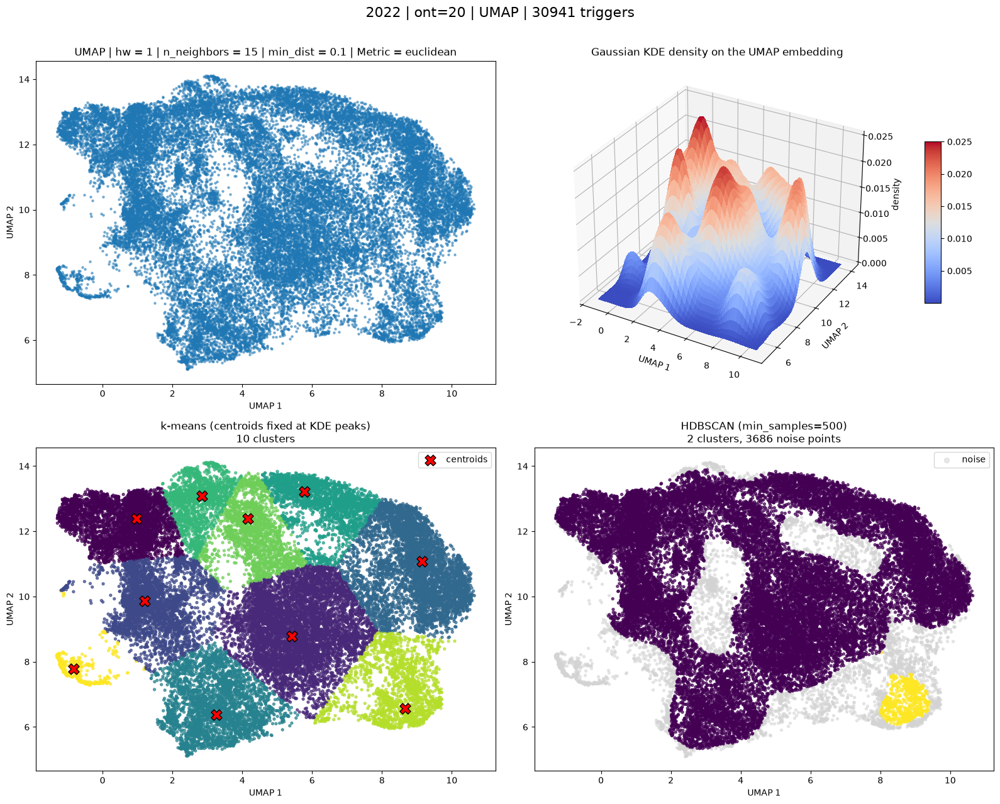

2022 ont=20 UMAP: k-means 10 clusters, HDBSCAN 2 clusters / 3686 noise
2022 ont=20: t-SNE loaded from TERZ_hw2_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw2_ont20_2022_umap_nn15_md0.1.npy


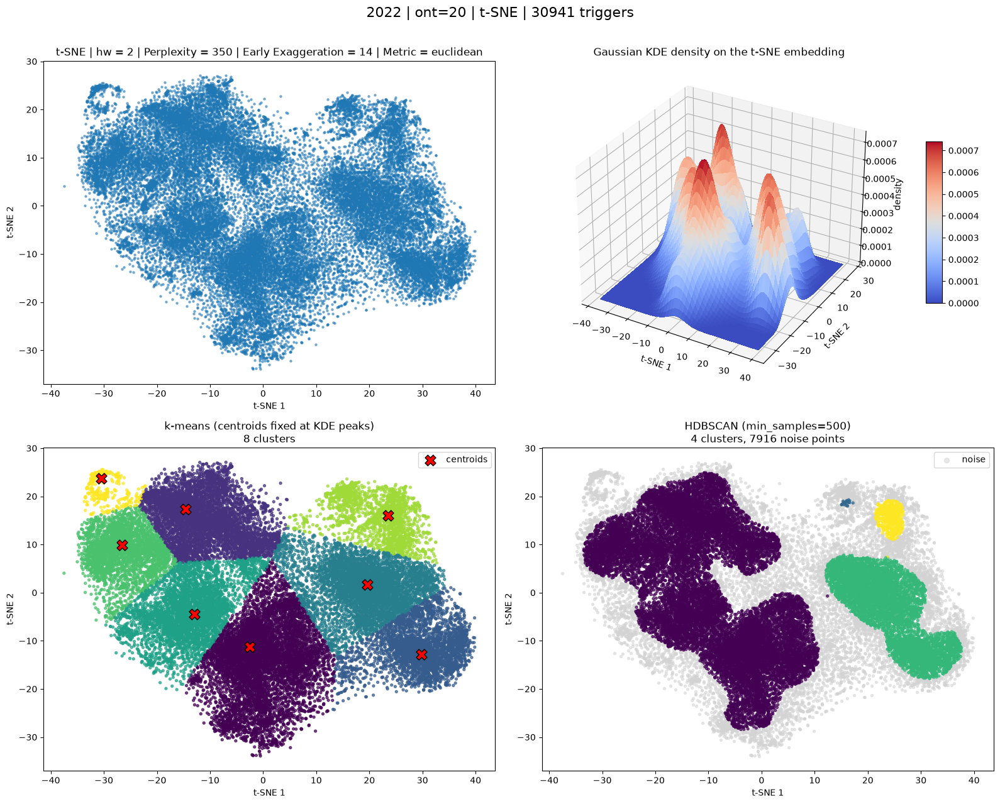

2022 ont=20 t-SNE: k-means 8 clusters, HDBSCAN 4 clusters / 7916 noise


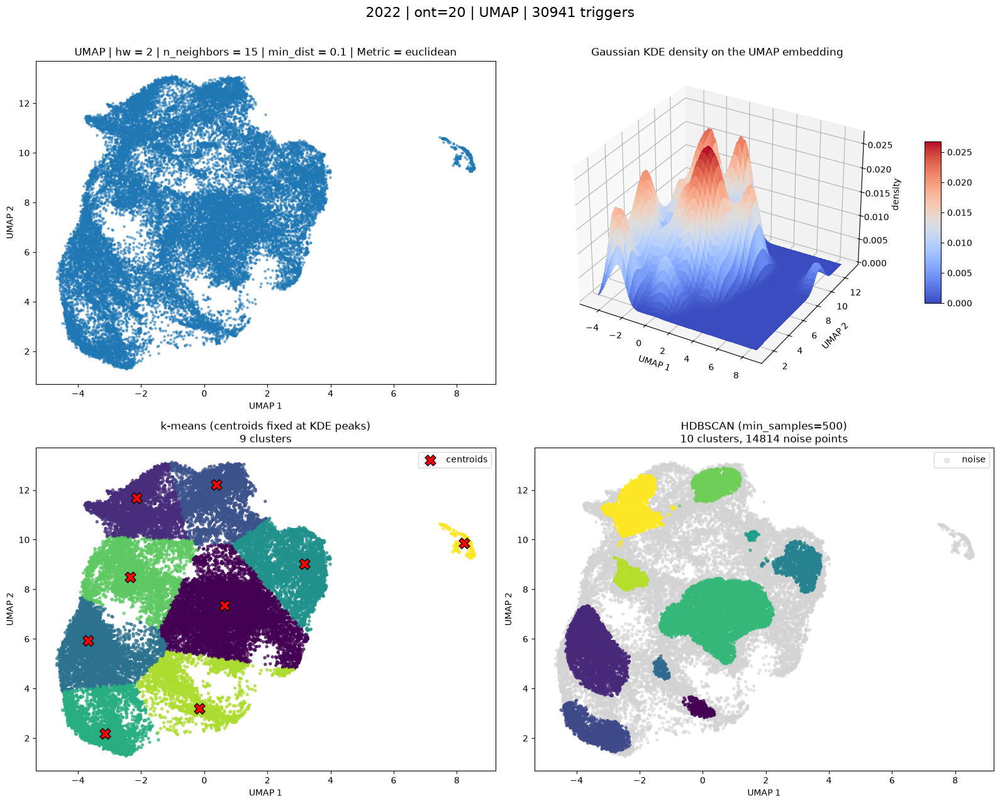

2022 ont=20 UMAP: k-means 9 clusters, HDBSCAN 10 clusters / 14814 noise
2022 ont=20: t-SNE loaded from TERZ_hw4_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw4_ont20_2022_umap_nn15_md0.1.npy


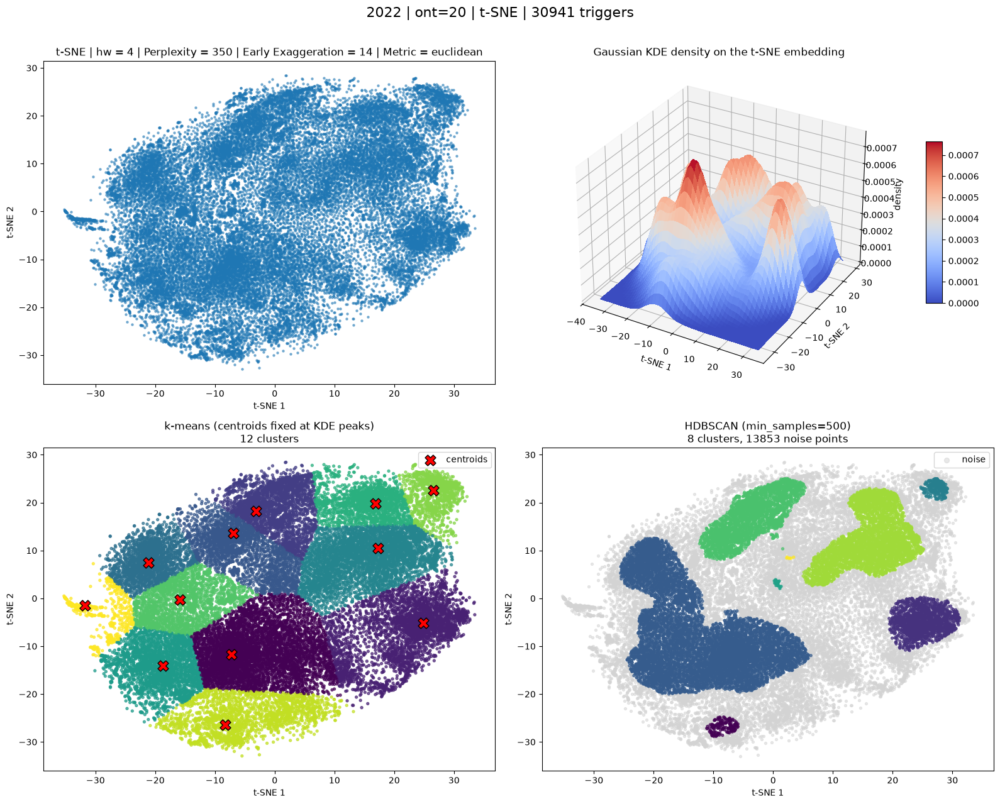

2022 ont=20 t-SNE: k-means 12 clusters, HDBSCAN 8 clusters / 13853 noise


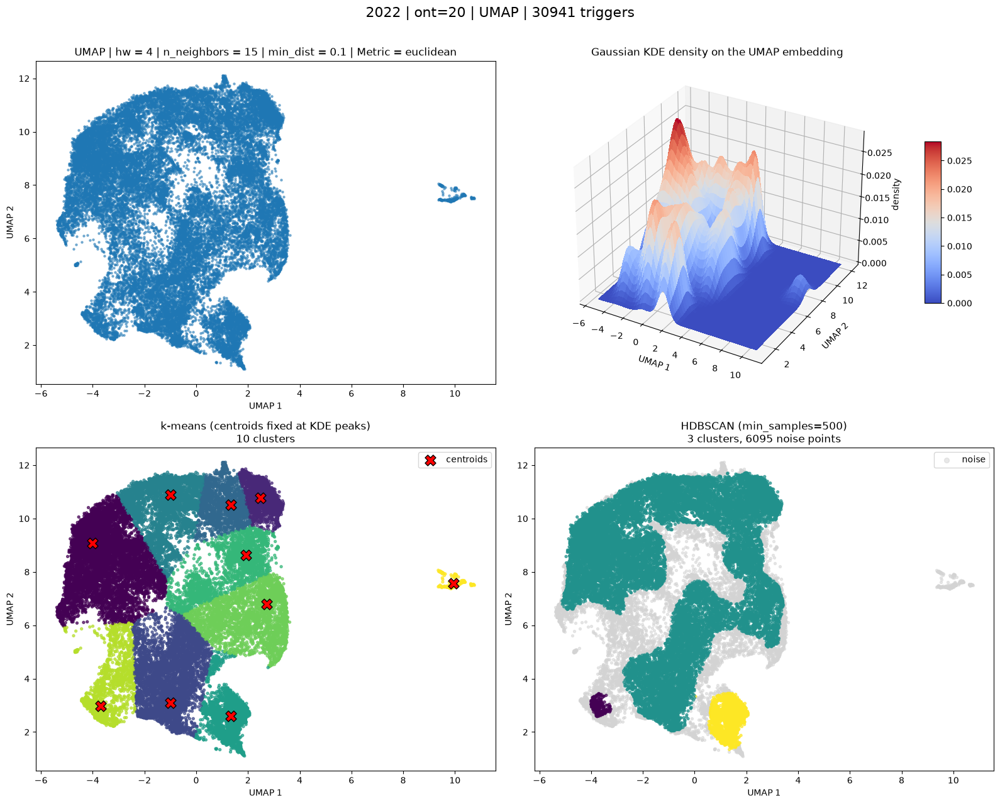

2022 ont=20 UMAP: k-means 10 clusters, HDBSCAN 3 clusters / 6095 noise
2022 ont=20: t-SNE loaded from TERZ_hw6_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw6_ont20_2022_umap_nn15_md0.1.npy


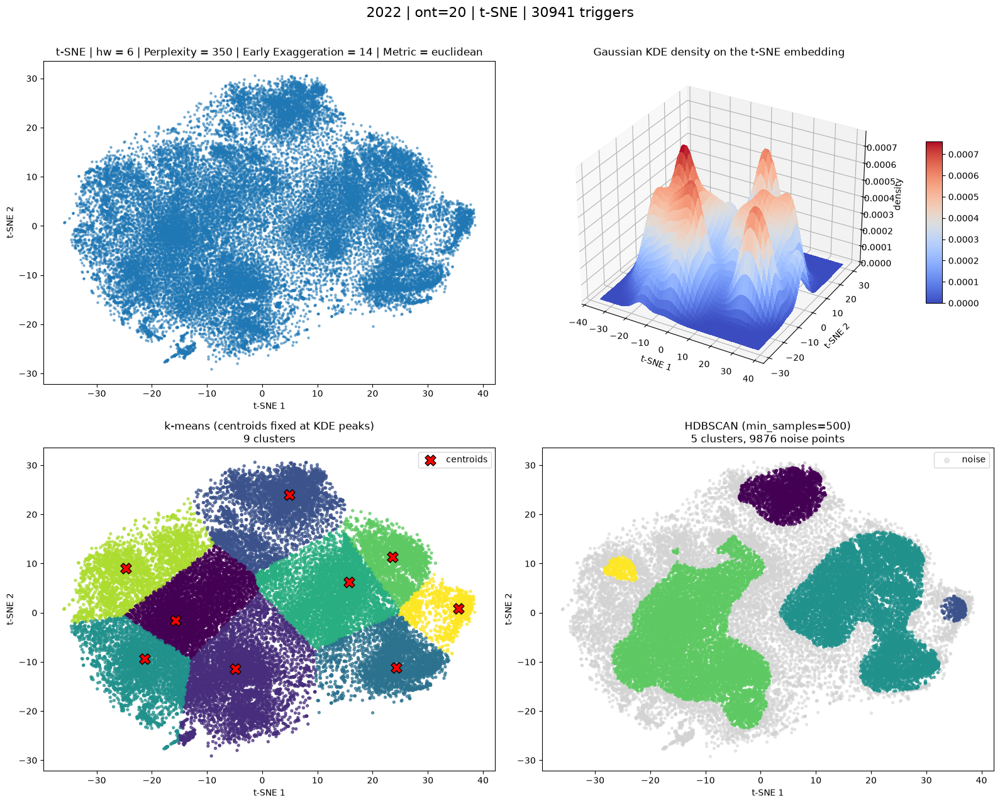

2022 ont=20 t-SNE: k-means 9 clusters, HDBSCAN 5 clusters / 9876 noise


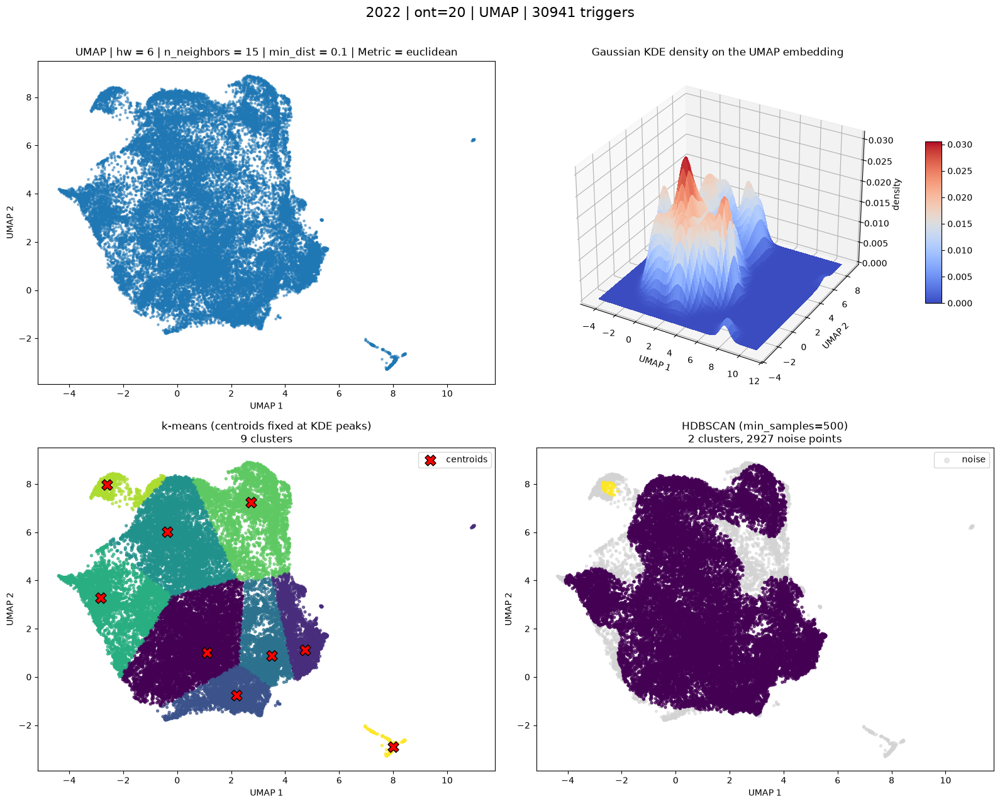

2022 ont=20 UMAP: k-means 9 clusters, HDBSCAN 2 clusters / 2927 noise
2022 ont=20: t-SNE loaded from TERZ_hw12_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw12_ont20_2022_umap_nn15_md0.1.npy


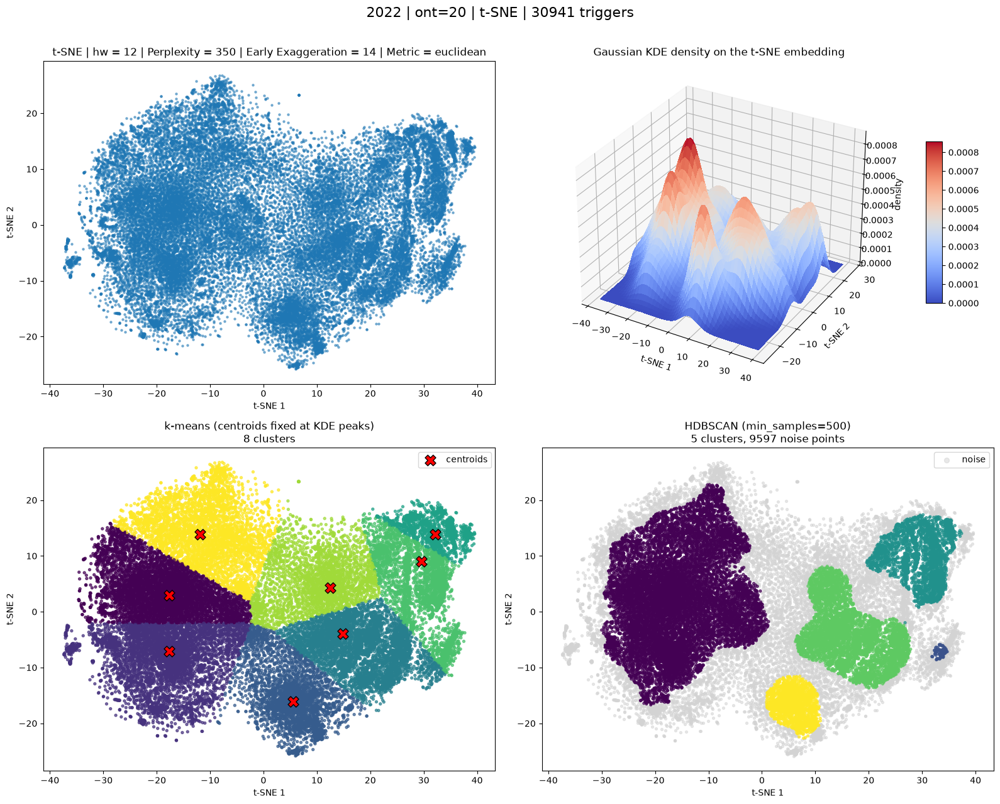

2022 ont=20 t-SNE: k-means 8 clusters, HDBSCAN 5 clusters / 9597 noise


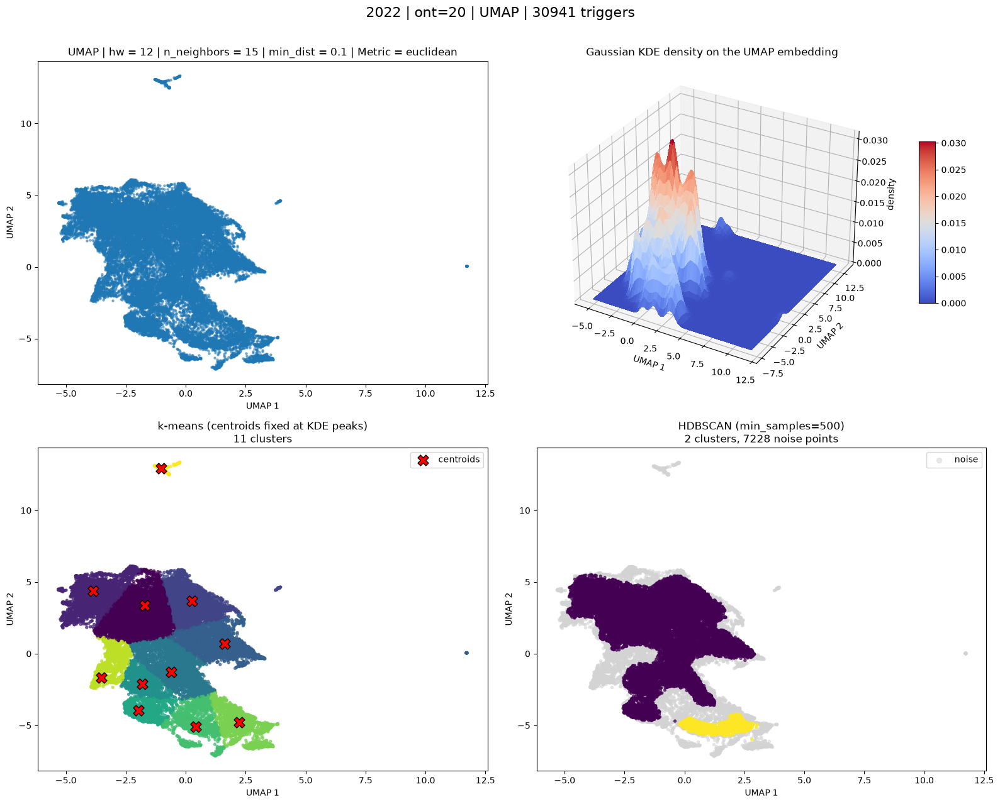

2022 ont=20 UMAP: k-means 11 clusters, HDBSCAN 2 clusters / 7228 noise
2022 ont=25: t-SNE loaded from TERZ_hw1_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw1_ont25_2022_umap_nn15_md0.1.npy


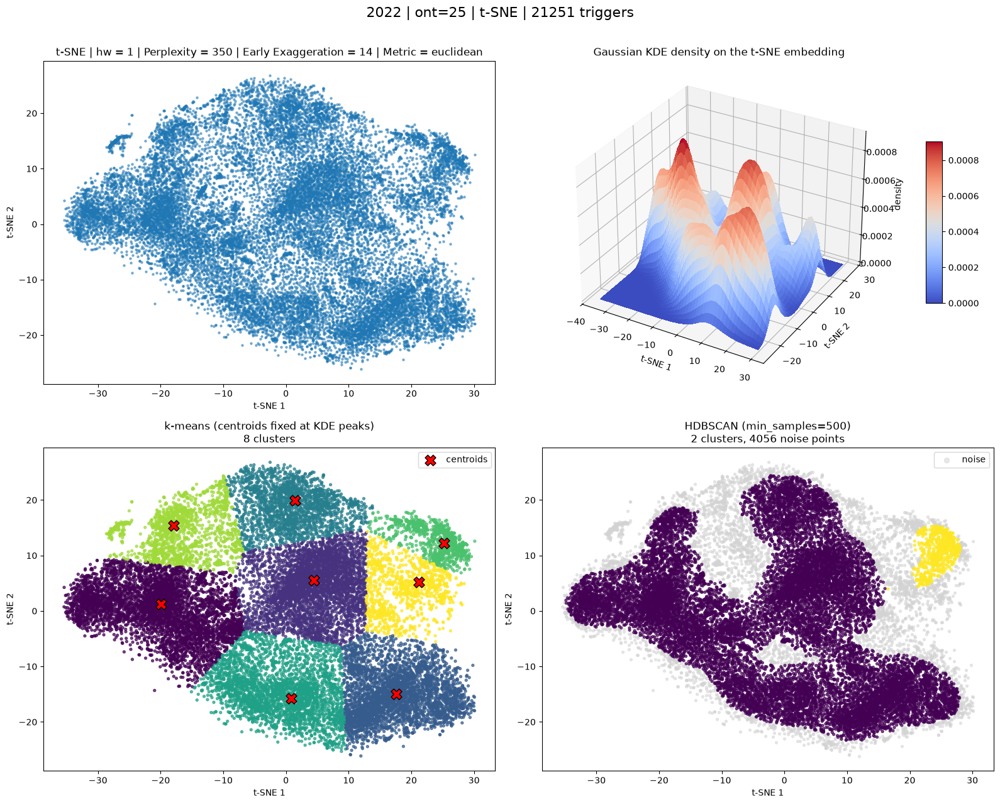

2022 ont=25 t-SNE: k-means 8 clusters, HDBSCAN 2 clusters / 4056 noise


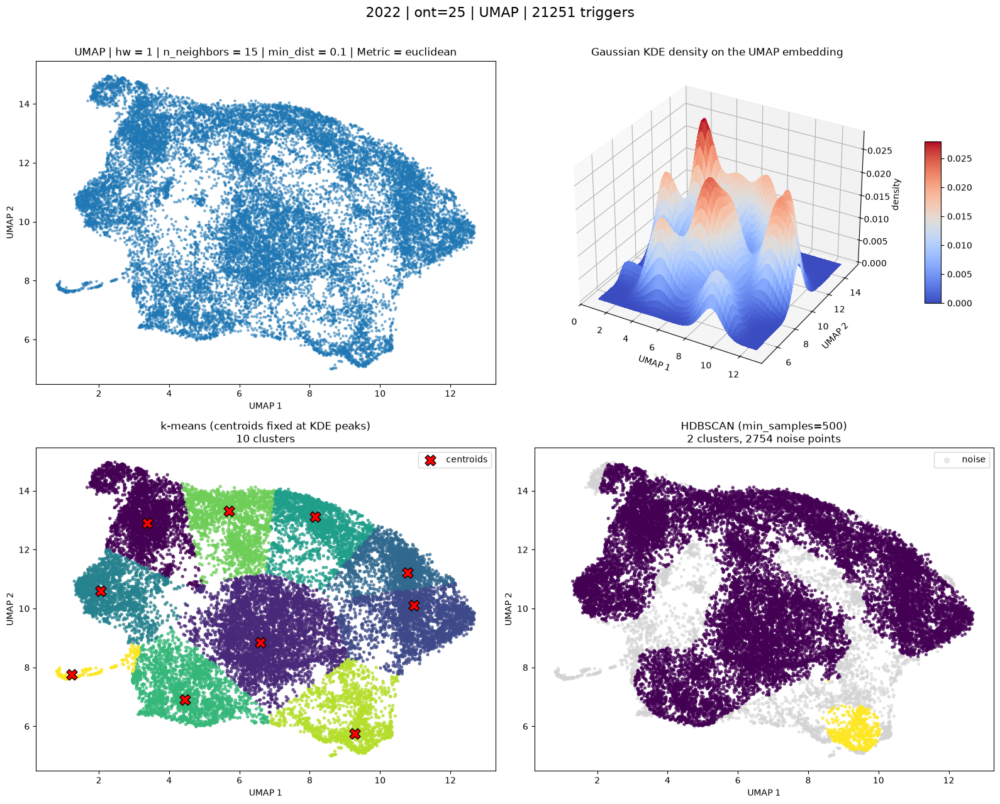

2022 ont=25 UMAP: k-means 10 clusters, HDBSCAN 2 clusters / 2754 noise
2022 ont=25: t-SNE loaded from TERZ_hw2_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw2_ont25_2022_umap_nn15_md0.1.npy


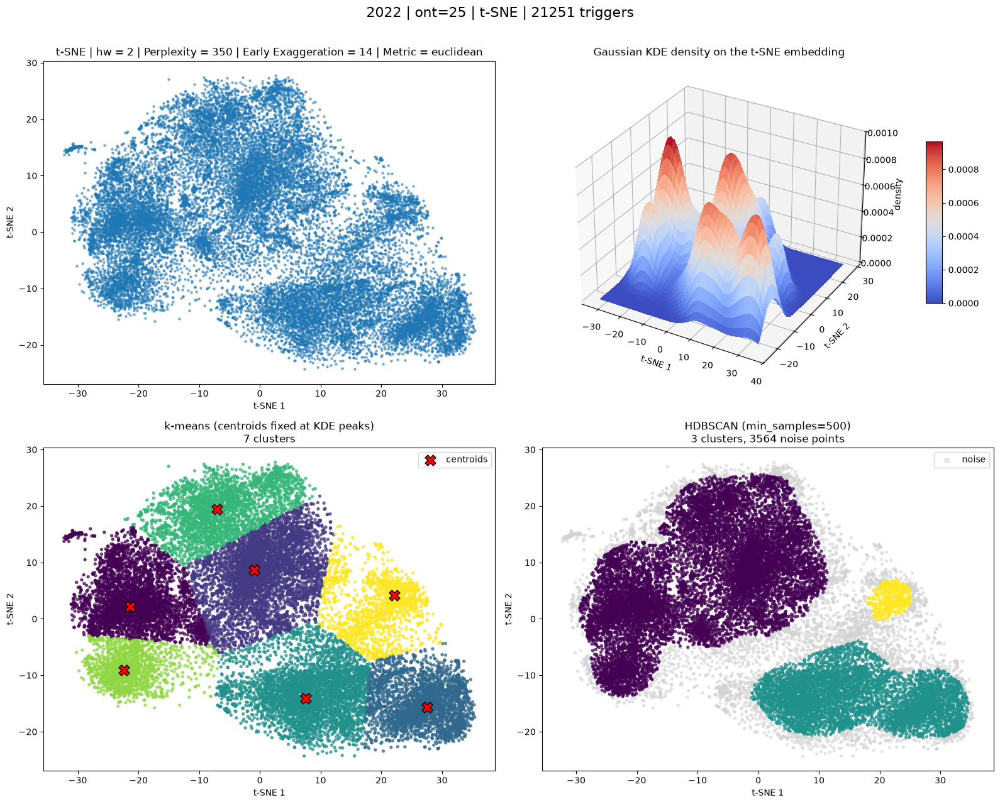

2022 ont=25 t-SNE: k-means 7 clusters, HDBSCAN 3 clusters / 3564 noise


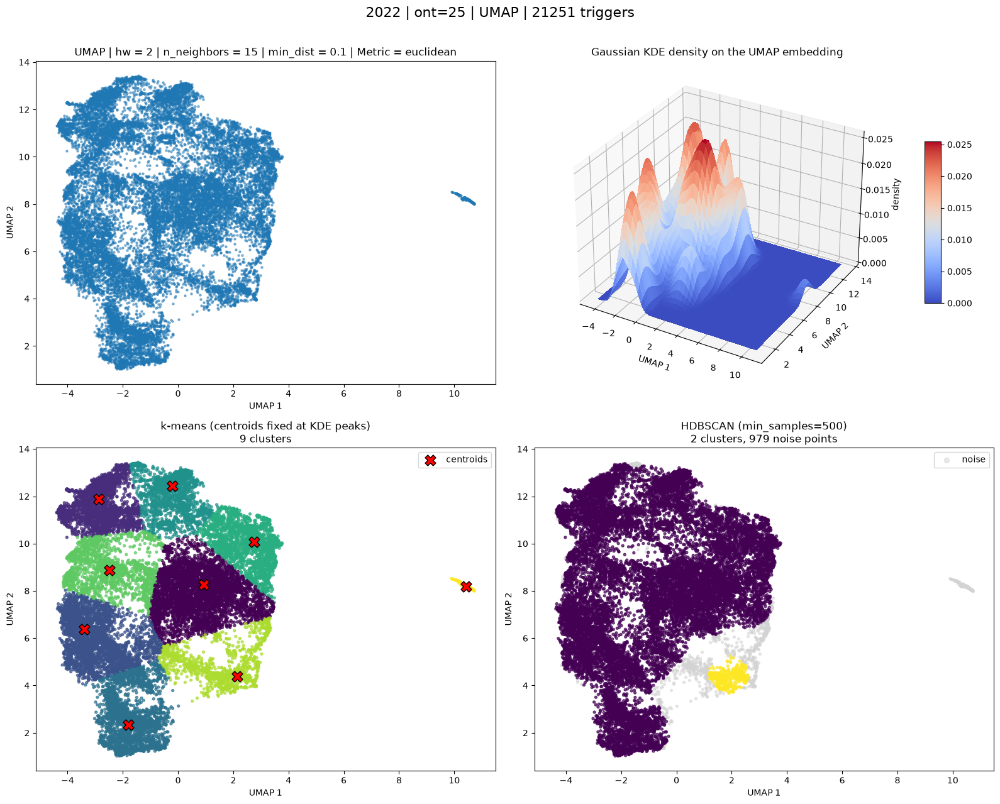

2022 ont=25 UMAP: k-means 9 clusters, HDBSCAN 2 clusters / 979 noise
2022 ont=25: t-SNE loaded from TERZ_hw4_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw4_ont25_2022_umap_nn15_md0.1.npy


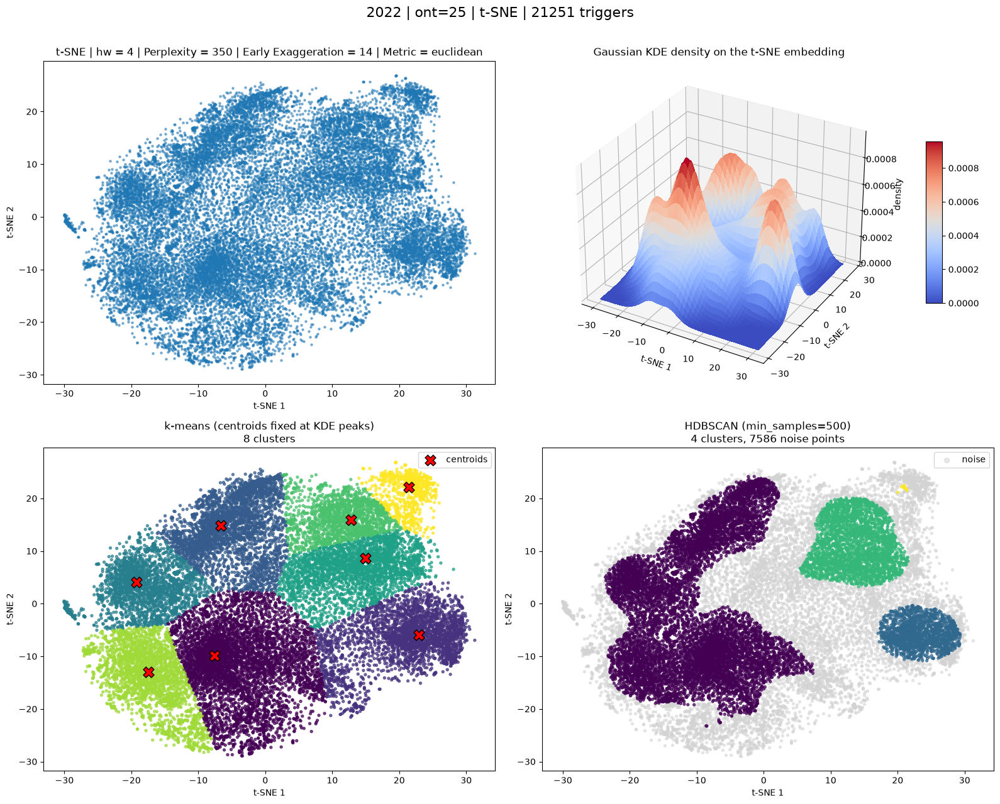

2022 ont=25 t-SNE: k-means 8 clusters, HDBSCAN 4 clusters / 7586 noise


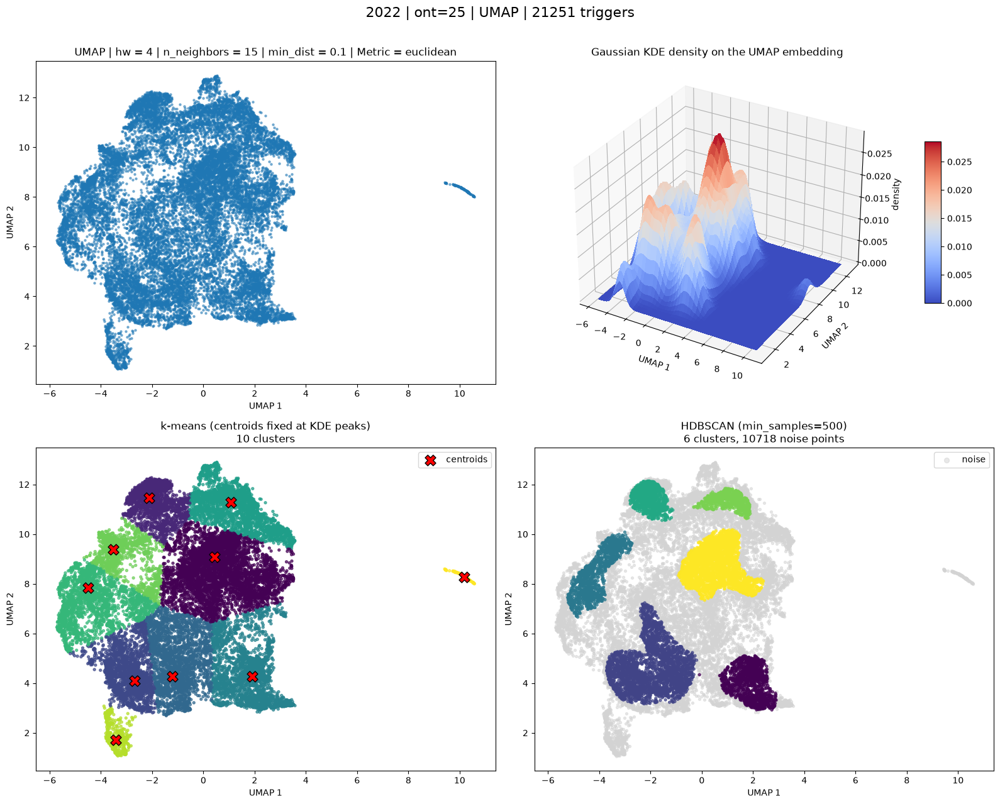

2022 ont=25 UMAP: k-means 10 clusters, HDBSCAN 6 clusters / 10718 noise
2022 ont=25: t-SNE loaded from TERZ_hw6_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw6_ont25_2022_umap_nn15_md0.1.npy


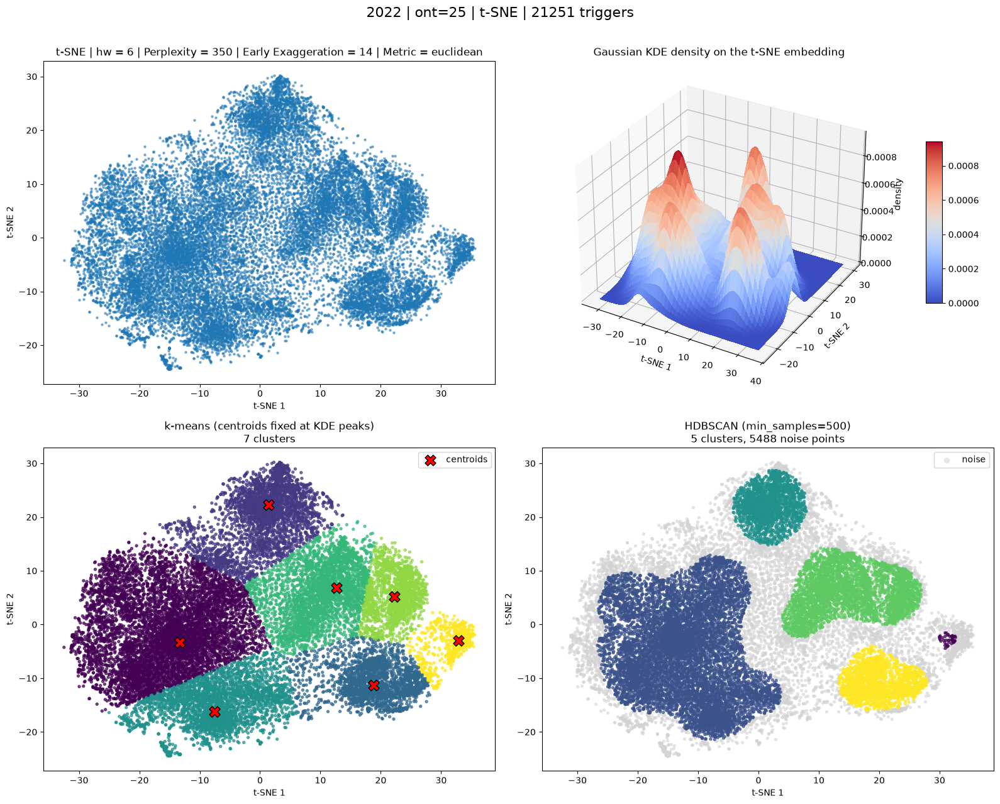

2022 ont=25 t-SNE: k-means 7 clusters, HDBSCAN 5 clusters / 5488 noise


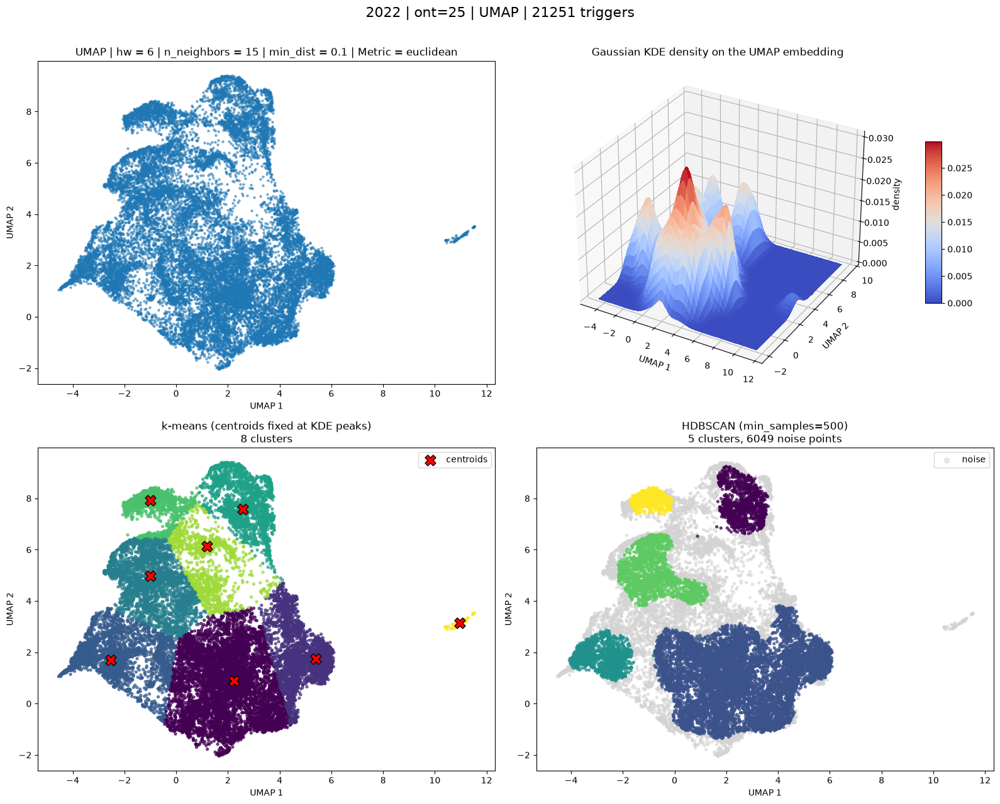

2022 ont=25 UMAP: k-means 8 clusters, HDBSCAN 5 clusters / 6049 noise
2022 ont=25: t-SNE loaded from TERZ_hw12_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw12_ont25_2022_umap_nn15_md0.1.npy


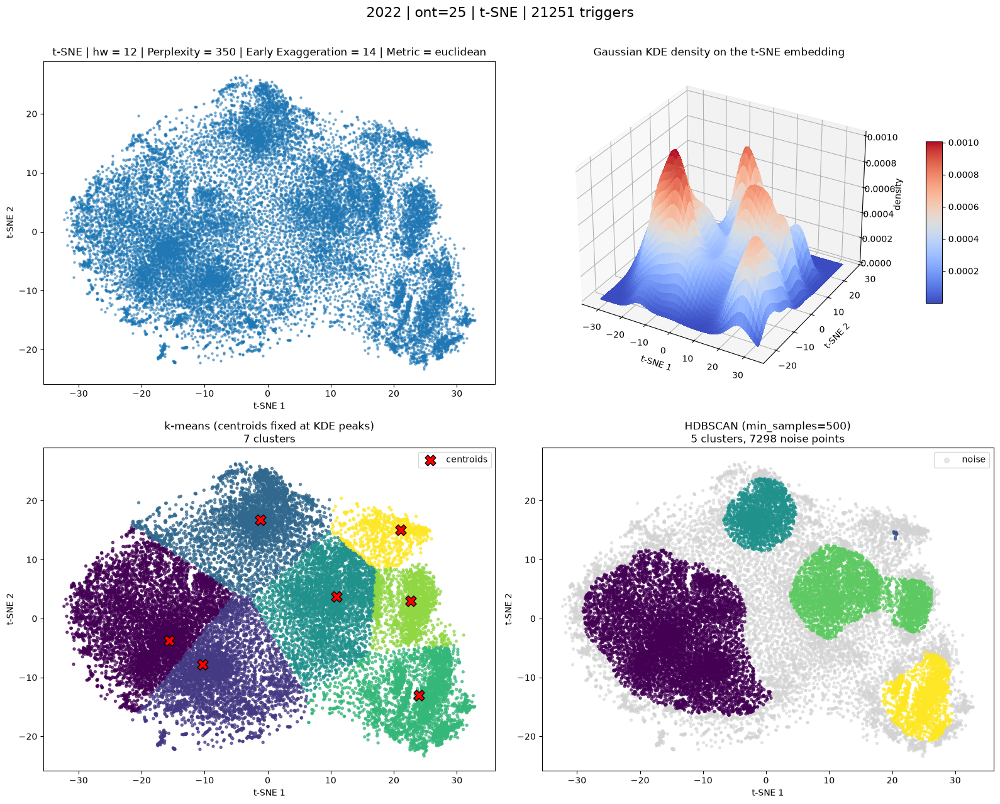

2022 ont=25 t-SNE: k-means 7 clusters, HDBSCAN 5 clusters / 7298 noise


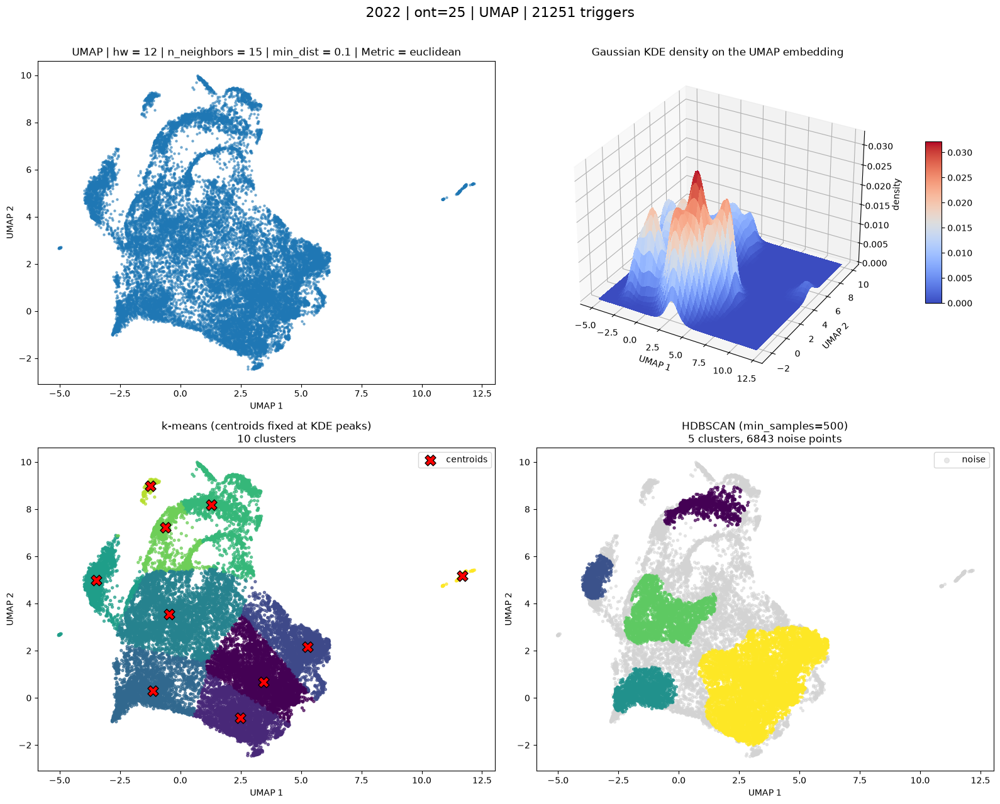

2022 ont=25 UMAP: k-means 10 clusters, HDBSCAN 5 clusters / 6843 noise


In [8]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run(year, ont, hw)

## Balanced subset and second embedding

For every dataset, the k-means clusters of the `LABEL_FROM` projection (the same clustering as the k-means panel above: centroids at the KDE peaks) are the labels. `PER_CLUSTER` triggers are drawn at random from every cluster (all of them if a cluster is smaller; this is printed), and t-SNE and UMAP are computed again on that subset. The features are normalised and standardised again using only the subset.

The selected row indices and labels are saved in `SUBSET_DIR` (`idx` = row positions in the parquet, `labels` = cluster of each selected row, `labels_full` = cluster of every row). The new embeddings are cached like the first ones; a cache file is ignored when the selection no longer matches. Colours are the first-round k-means labels, so the figure shows how well those clusters hold together in the new embedding.

In [9]:
def kmeans_cluster_labels(E, proj, year, ont):
    """k-means labels of one embedding, centroids at the KDE peaks (same clustering as the k-means panel)."""
    params = {**CLUSTER_PARAMS[proj], **CLUSTER_OVERRIDES.get((year, ont, proj), {})}
    X, Y, Z = density_surface(E)
    peaks, _ = kde_peaks(X, Y, Z, params["kde_peak_size"], params["kde_peak_min_rel"])
    labels, _ = kmeans_labels(E, peaks)
    return labels


def balanced_indices(labels, per_cluster):
    """Sorted row indices: `per_cluster` random rows from every cluster (all rows if it has fewer)."""
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = []
    for k in np.unique(labels):
        members = np.flatnonzero(labels == k)
        if len(members) < per_cluster:
            print(f"    cluster {k}: only {len(members)} triggers, taking all of them")
        chosen.append(rng.choice(members, size=min(per_cluster, len(members)), replace=False))
    return np.sort(np.concatenate(chosen))


def get_subset(year, ont, hw):
    """Balanced subset of one dataset -> (row indices, labels of those rows, labels of all rows)."""
    E = get_embeddings(year, ont, hw)[LABEL_FROM]
    labels_full = kmeans_cluster_labels(E, LABEL_FROM, year, ont)
    print(f"{year} ont={ont} hw={hw}: {len(np.unique(labels_full))} k-means clusters on the "
          f"{PROJECTIONS[LABEL_FROM]} embedding, sizes {np.bincount(labels_full).tolist()}")
    idx = balanced_indices(labels_full, PER_CLUSTER)
    np.savez(SUBSET_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_sub{PER_CLUSTER}_{LABEL_FROM}.npz",
             idx=idx, labels=labels_full[idx], labels_full=labels_full)
    return idx, labels_full[idx]


def subset_tsne(X_scaled):
    return TSNE(n_components=2, perplexity=SUB_PERPLEXITY, early_exaggeration=SUB_EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE,
                metric=METRIC).fit_transform(X_scaled)


def subset_umap(X_scaled):
    import umap
    return umap.UMAP(n_components=2, n_neighbors=SUB_UMAP_N_NEIGHBORS, min_dist=SUB_UMAP_MIN_DIST,
                     metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_scaled)


SUBSET_COMPUTE = {"tsne": subset_tsne, "umap": subset_umap}


def subset_cache_path(year, ont, hw, projection):
    if projection == "tsne":
        tag = f"tsne_perp{SUB_PERPLEXITY}_ee{SUB_EARLY_EXAGGERATION}"
    else:
        tag = f"umap_nn{SUB_UMAP_N_NEIGHBORS}_md{SUB_UMAP_MIN_DIST}"
    return CACHE_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_sub{PER_CLUSTER}_{LABEL_FROM}_{tag}.npz"


def get_subset_embeddings(year, ont, hw, idx):
    """Return {"tsne": (m, 2), "umap": (m, 2)} for the rows `idx`; computes and caches whatever is missing."""
    paths = {proj: subset_cache_path(year, ont, hw, proj) for proj in SUBSET_COMPUTE}
    embeddings = {}
    for proj, path in paths.items():
        embeddings[proj] = None
        if path.exists():
            with np.load(path) as saved:
                if np.array_equal(saved["idx"], idx):          # the cached embedding belongs to this selection
                    embeddings[proj] = saved["embedding"]
                    print(f"{year} ont={ont} hw={hw}: subset {PROJECTIONS[proj]} loaded from {path.name}")

    missing = [proj for proj, E in embeddings.items() if E is None]
    if missing:
        X_scaled = feature_matrix(year, ont, hw, rows=idx)
        for proj in missing:
            print(f"{year} ont={ont} hw={hw}: computing subset {PROJECTIONS[proj]} ...")
            embeddings[proj] = SUBSET_COMPUTE[proj](X_scaled)
            np.savez(paths[proj], embedding=embeddings[proj], idx=idx)
    return embeddings


def plot_subset(embeddings, labels, year, ont, hw):
    """One figure: t-SNE | UMAP of the balanced subset, coloured by the first-round k-means cluster."""
    clusters = np.unique(labels)
    cmap = plt.get_cmap("tab10" if len(clusters) <= 10 else "tab20")
    titles = {
        "tsne": f"t-SNE | Perplexity = {SUB_PERPLEXITY} | Early Exaggeration = {SUB_EARLY_EXAGGERATION} | Metric = {METRIC}",
        "umap": f"UMAP | n_neighbors = {SUB_UMAP_N_NEIGHBORS} | min_dist = {SUB_UMAP_MIN_DIST} | Metric = {METRIC}",
    }

    fig, axes = plt.subplots(1, len(PROJECTIONS), figsize=(8 * len(PROJECTIONS), 7))
    for ax, (proj, name) in zip(np.atleast_1d(axes), PROJECTIONS.items()):
        E = embeddings[proj]
        for i, k in enumerate(clusters):
            m = labels == k
            ax.scatter(E[m, 0], E[m, 1], s=6, alpha=0.6, color=cmap(i % cmap.N), label=f"cluster {k} (n={m.sum()})")
        ax.set_title(titles[proj], fontsize=10)
        ax.set_xlabel(f"{name} 1")
        ax.set_ylabel(f"{name} 2")
        ax.legend(loc="best", markerscale=3, fontsize=8)

    fig.suptitle(f"{year} | ont={ont} | hw = {hw} | {len(labels)} triggers, up to {PER_CLUSTER} per k-means cluster "
                 f"(labels from {PROJECTIONS[LABEL_FROM]})", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_subset_{LABEL_FROM}labels.png", dpi=150)
    plt.show()
    plt.close(fig)


def run_subset(year, ont, hw):
    idx, labels = get_subset(year, ont, hw)
    embeddings = get_subset_embeddings(year, ont, hw, idx)
    plot_subset(embeddings, labels, year, ont, hw)


In [10]:
SUB_PERPLEXITY = 100

2022 ont=15: t-SNE loaded from TERZ_hw1_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw1_ont15_2022_umap_nn15_md0.1.npy
2022 ont=15 hw=1: 12 k-means clusters on the t-SNE embedding, sizes [8726, 5477, 5593, 3100, 3948, 4807, 4290, 2328, 3833, 3080, 2864, 1553]
2022 ont=15 hw=1: subset t-SNE loaded from TERZ_hw1_ont15_2022_sub1000_tsne_tsne_perp100_ee14.npz
2022 ont=15 hw=1: subset UMAP loaded from TERZ_hw1_ont15_2022_sub1000_tsne_umap_nn15_md0.1.npz


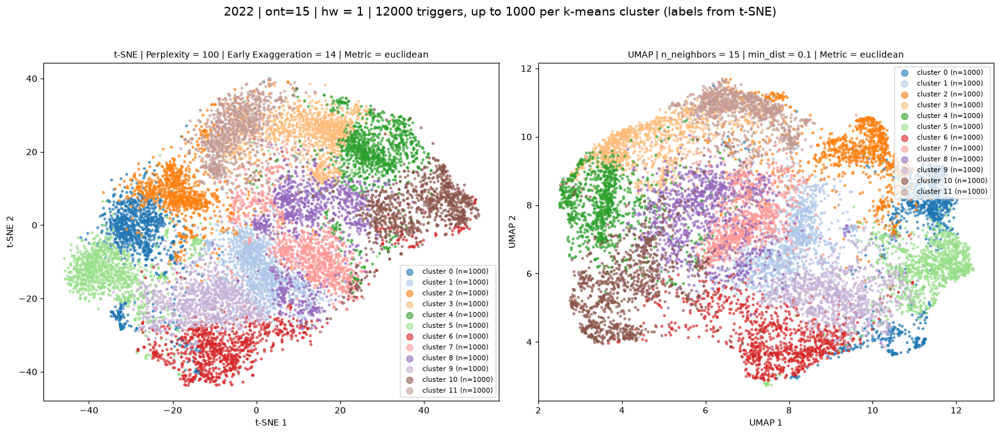

2022 ont=15: t-SNE loaded from TERZ_hw2_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw2_ont15_2022_umap_nn15_md0.1.npy
2022 ont=15 hw=2: 10 k-means clusters on the t-SNE embedding, sizes [10279, 6086, 6015, 4282, 4459, 4730, 4275, 3673, 3374, 2426]
2022 ont=15 hw=2: subset t-SNE loaded from TERZ_hw2_ont15_2022_sub1000_tsne_tsne_perp100_ee14.npz
2022 ont=15 hw=2: subset UMAP loaded from TERZ_hw2_ont15_2022_sub1000_tsne_umap_nn15_md0.1.npz


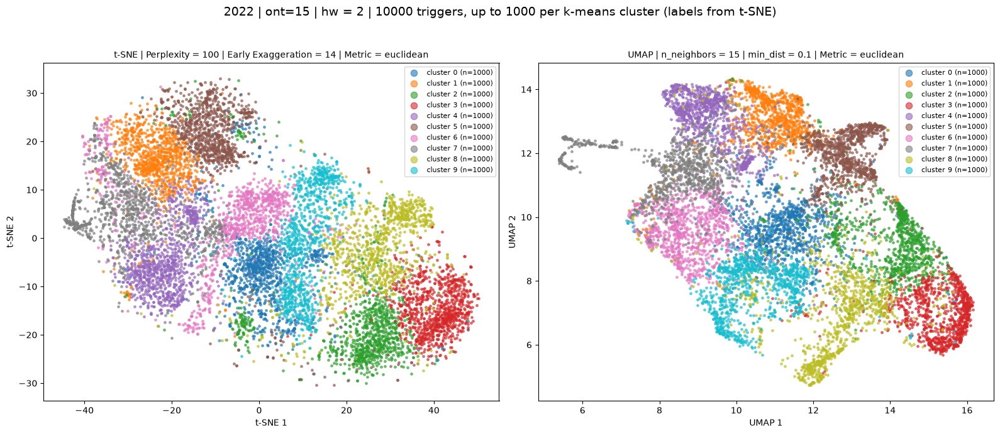

2022 ont=15: t-SNE loaded from TERZ_hw4_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw4_ont15_2022_umap_nn15_md0.1.npy
2022 ont=15 hw=4: 14 k-means clusters on the t-SNE embedding, sizes [6008, 3325, 4053, 4390, 3744, 4653, 3398, 3982, 2197, 3714, 1811, 3255, 3598, 1471]
2022 ont=15 hw=4: subset t-SNE loaded from TERZ_hw4_ont15_2022_sub1000_tsne_tsne_perp100_ee14.npz
2022 ont=15 hw=4: subset UMAP loaded from TERZ_hw4_ont15_2022_sub1000_tsne_umap_nn15_md0.1.npz


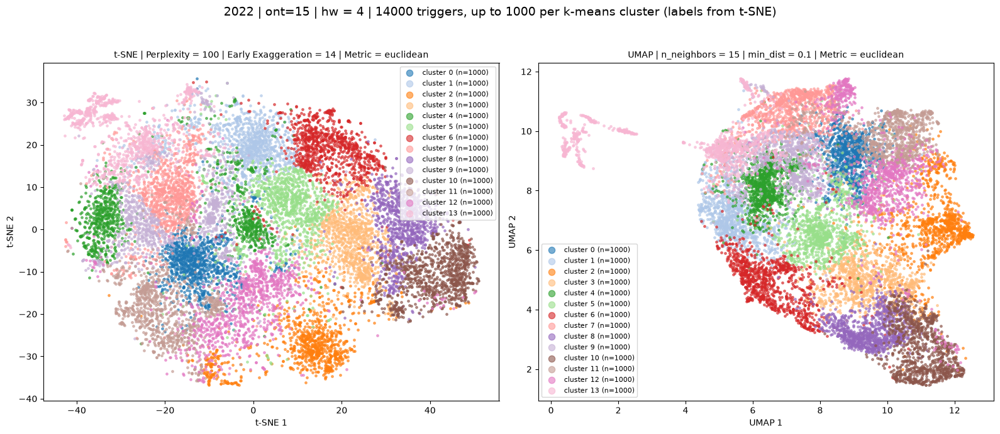

2022 ont=15: t-SNE loaded from TERZ_hw6_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw6_ont15_2022_umap_nn15_md0.1.npy
2022 ont=15 hw=6: 9 k-means clusters on the t-SNE embedding, sizes [14167, 4813, 7583, 4045, 3098, 4294, 4273, 3326, 4000]
2022 ont=15 hw=6: subset t-SNE loaded from TERZ_hw6_ont15_2022_sub1000_tsne_tsne_perp100_ee14.npz
2022 ont=15 hw=6: subset UMAP loaded from TERZ_hw6_ont15_2022_sub1000_tsne_umap_nn15_md0.1.npz


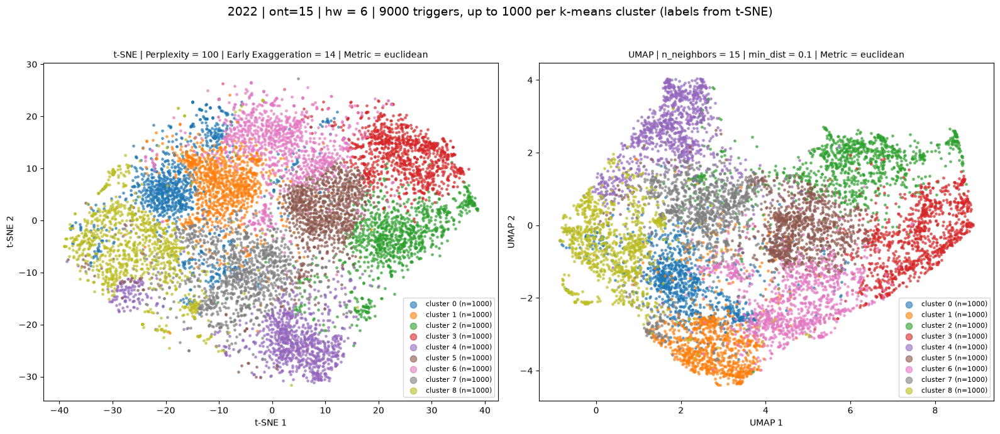

2022 ont=15: t-SNE loaded from TERZ_hw12_ont15_2022_tsne_perp350_ee14.npy
2022 ont=15: UMAP loaded from TERZ_hw12_ont15_2022_umap_nn15_md0.1.npy
2022 ont=15 hw=12: 10 k-means clusters on the t-SNE embedding, sizes [10872, 6473, 3653, 6906, 3516, 4230, 2867, 2851, 5597, 2634]
2022 ont=15 hw=12: subset t-SNE loaded from TERZ_hw12_ont15_2022_sub1000_tsne_tsne_perp100_ee14.npz
2022 ont=15 hw=12: subset UMAP loaded from TERZ_hw12_ont15_2022_sub1000_tsne_umap_nn15_md0.1.npz


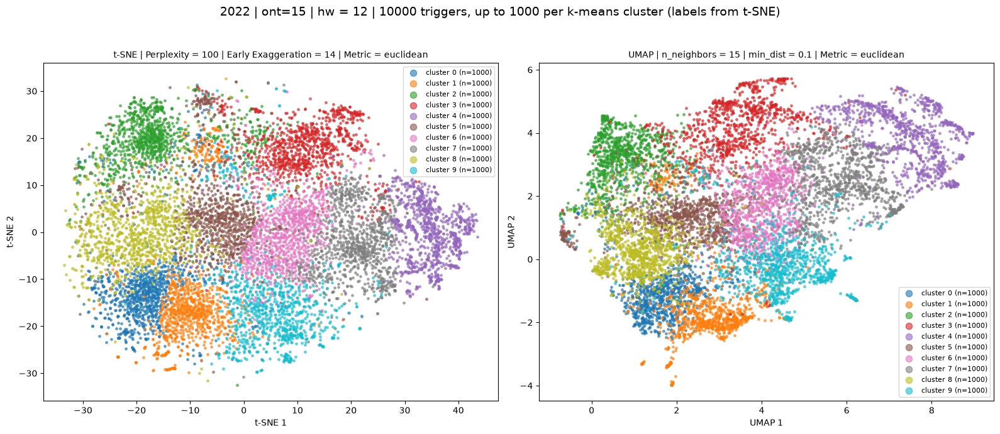

2022 ont=20: t-SNE loaded from TERZ_hw1_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw1_ont20_2022_umap_nn15_md0.1.npy
2022 ont=20 hw=1: 10 k-means clusters on the t-SNE embedding, sizes [3953, 4693, 4640, 2468, 2900, 3700, 1752, 2216, 2247, 2372]
2022 ont=20: 10000 triggers, 1230 features
2022 ont=20 hw=1: computing subset t-SNE ...
2022 ont=20 hw=1: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


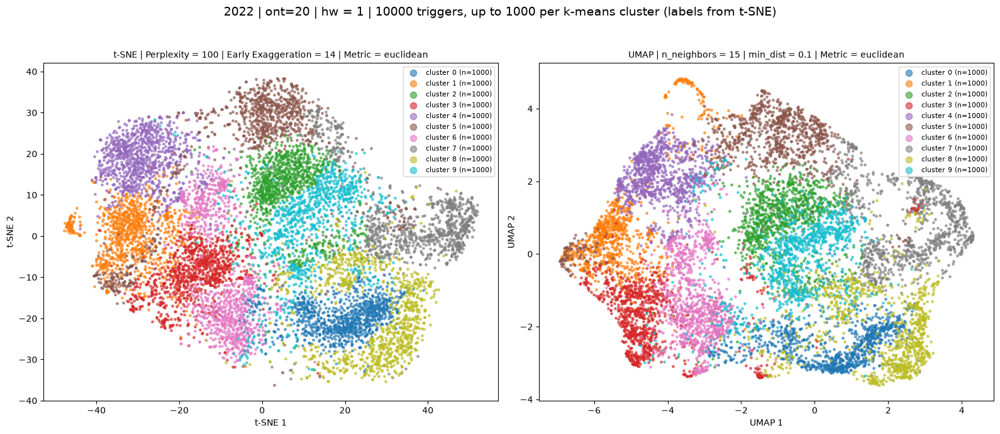

2022 ont=20: t-SNE loaded from TERZ_hw2_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw2_ont20_2022_umap_nn15_md0.1.npy
2022 ont=20 hw=2: 8 k-means clusters on the t-SNE embedding, sizes [7190, 5422, 3552, 4799, 4310, 3101, 2049, 518]
    cluster 7: only 518 triggers, taking all of them
2022 ont=20: 7518 triggers, 1230 features
2022 ont=20 hw=2: computing subset t-SNE ...
2022 ont=20 hw=2: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


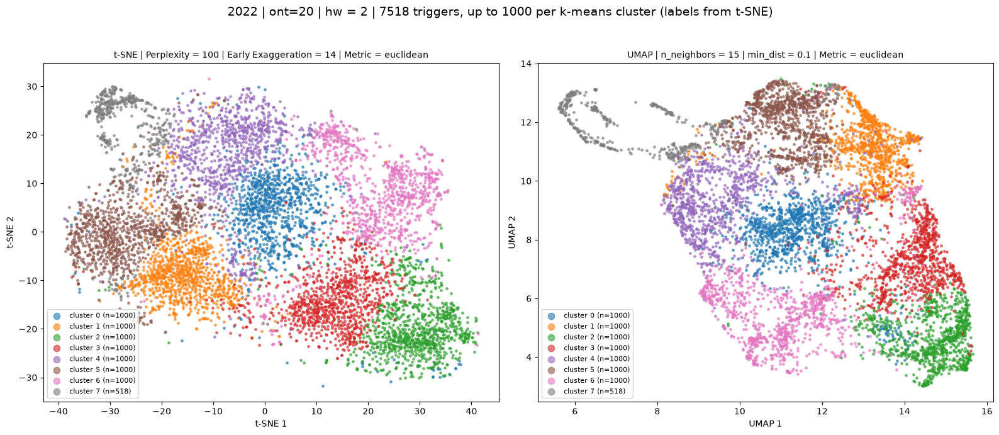

2022 ont=20: t-SNE loaded from TERZ_hw4_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw4_ont20_2022_umap_nn15_md0.1.npy
2022 ont=20 hw=4: 12 k-means clusters on the t-SNE embedding, sizes [5298, 3623, 2668, 2582, 2007, 4047, 2697, 1762, 2279, 1123, 2190, 665]
    cluster 11: only 665 triggers, taking all of them
2022 ont=20: 11665 triggers, 1230 features
2022 ont=20 hw=4: computing subset t-SNE ...
2022 ont=20 hw=4: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


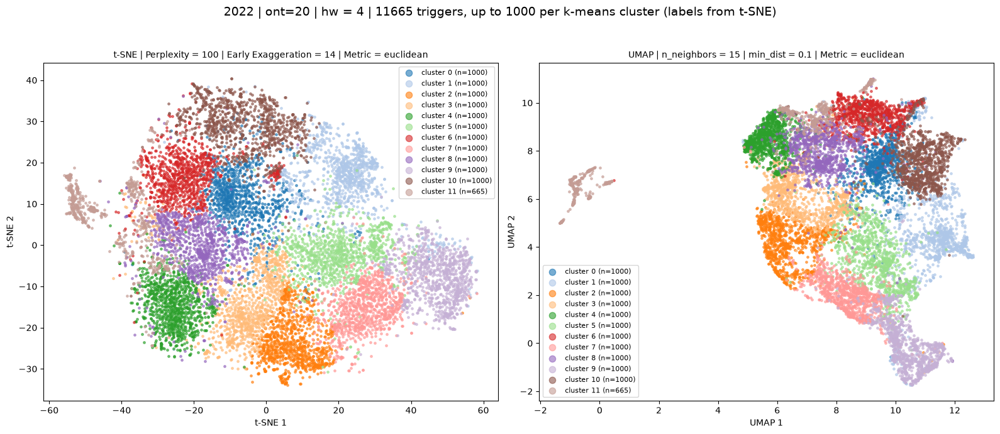

2022 ont=20: t-SNE loaded from TERZ_hw6_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw6_ont20_2022_umap_nn15_md0.1.npy
2022 ont=20 hw=6: 9 k-means clusters on the t-SNE embedding, sizes [4493, 5547, 3961, 3171, 3458, 4334, 2175, 2695, 1107]
2022 ont=20: 9000 triggers, 1230 features
2022 ont=20 hw=6: computing subset t-SNE ...
2022 ont=20 hw=6: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


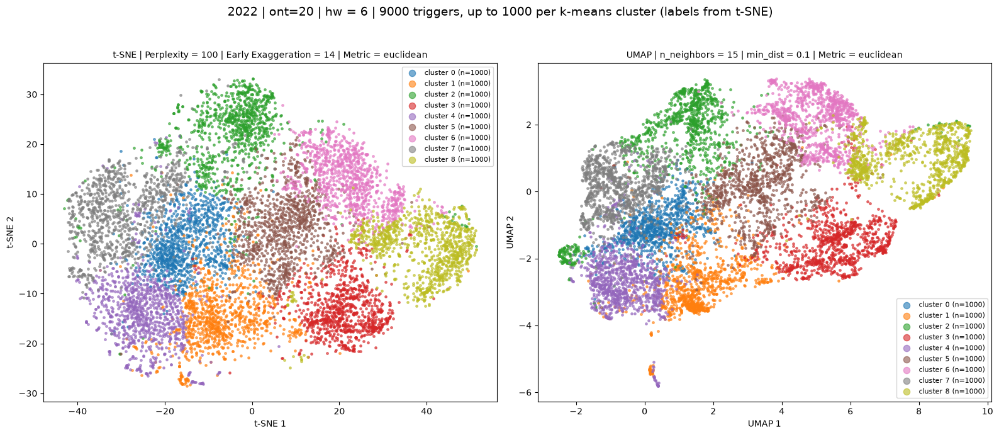

2022 ont=20: t-SNE loaded from TERZ_hw12_ont20_2022_tsne_perp350_ee14.npy
2022 ont=20: UMAP loaded from TERZ_hw12_ont20_2022_umap_nn15_md0.1.npy
2022 ont=20 hw=12: 8 k-means clusters on the t-SNE embedding, sizes [5549, 5475, 3429, 4730, 1514, 3145, 2922, 4177]
2022 ont=20: 8000 triggers, 1230 features
2022 ont=20 hw=12: computing subset t-SNE ...
2022 ont=20 hw=12: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


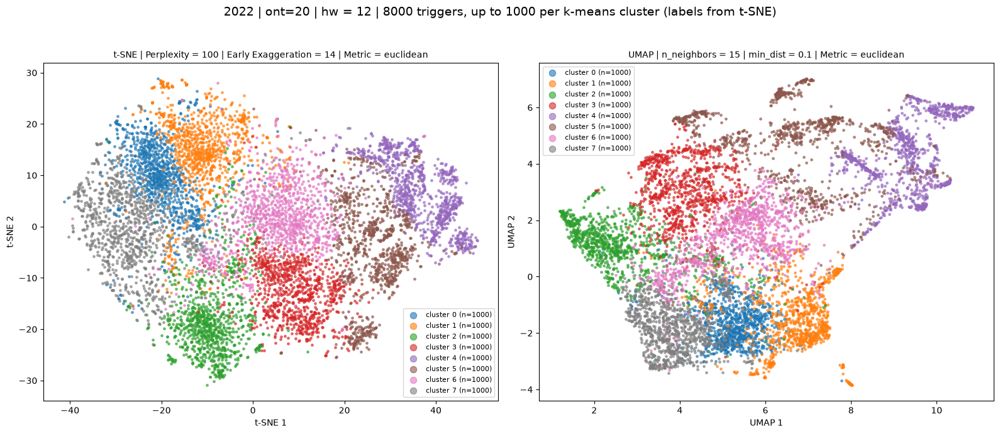

2022 ont=25: t-SNE loaded from TERZ_hw1_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw1_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=1: 8 k-means clusters on the t-SNE embedding, sizes [4977, 3843, 3590, 2106, 3042, 908, 1690, 1095]
    cluster 5: only 908 triggers, taking all of them
2022 ont=25: 7908 triggers, 1230 features
2022 ont=25 hw=1: computing subset t-SNE ...
2022 ont=25 hw=1: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


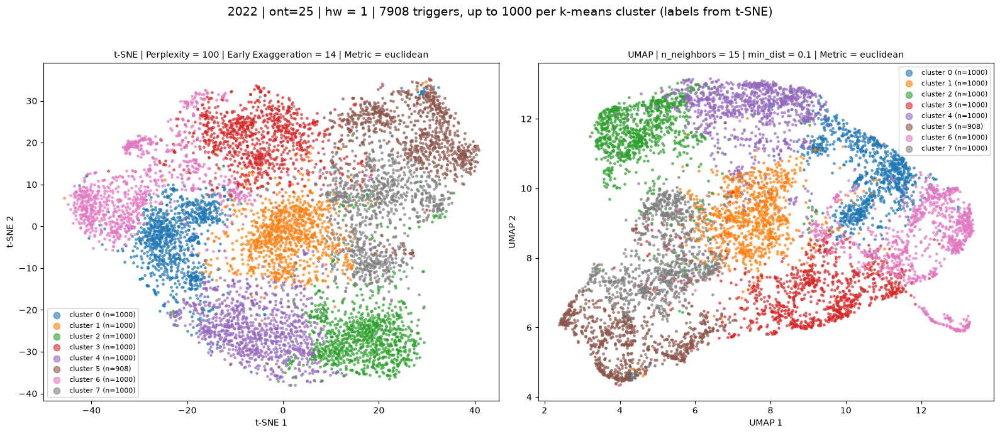

2022 ont=25: t-SNE loaded from TERZ_hw2_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw2_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=2: 7 k-means clusters on the t-SNE embedding, sizes [4010, 4550, 2891, 3888, 2829, 1512, 1571]
2022 ont=25: 7000 triggers, 1230 features
2022 ont=25 hw=2: computing subset t-SNE ...
2022 ont=25 hw=2: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


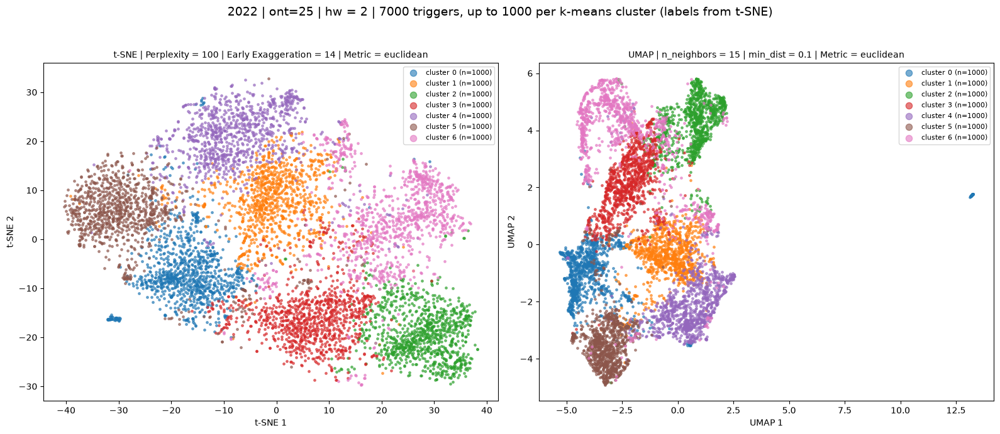

2022 ont=25: t-SNE loaded from TERZ_hw4_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw4_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=4: 8 k-means clusters on the t-SNE embedding, sizes [4987, 2931, 3333, 2370, 2696, 1678, 2488, 768]
    cluster 7: only 768 triggers, taking all of them
2022 ont=25: 7768 triggers, 1230 features
2022 ont=25 hw=4: computing subset t-SNE ...
2022 ont=25 hw=4: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


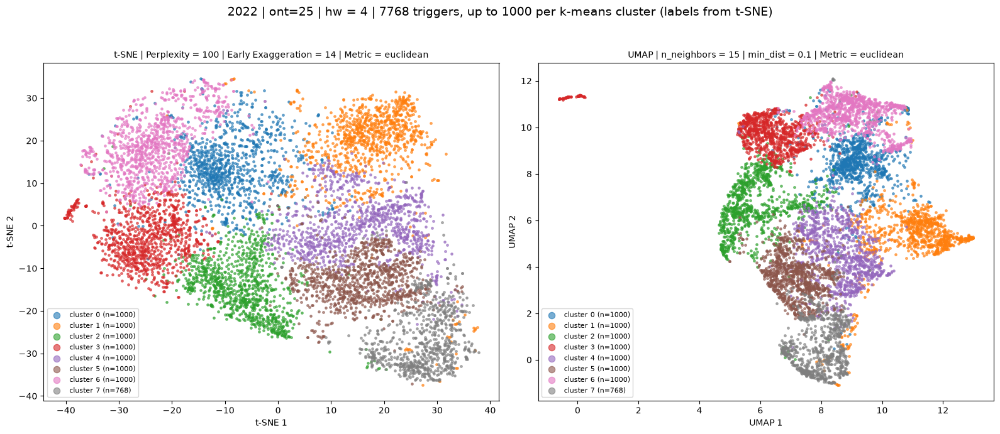

2022 ont=25: t-SNE loaded from TERZ_hw6_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw6_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=6: 7 k-means clusters on the t-SNE embedding, sizes [6928, 3115, 2431, 3266, 3159, 1667, 685]
    cluster 6: only 685 triggers, taking all of them
2022 ont=25: 6685 triggers, 1230 features
2022 ont=25 hw=6: computing subset t-SNE ...
2022 ont=25 hw=6: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


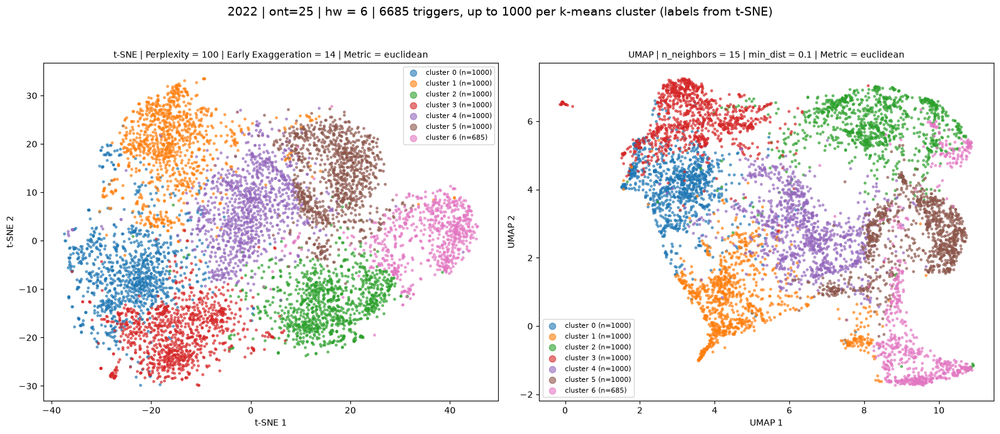

2022 ont=25: t-SNE loaded from TERZ_hw12_ont25_2022_tsne_perp350_ee14.npy
2022 ont=25: UMAP loaded from TERZ_hw12_ont25_2022_umap_nn15_md0.1.npy
2022 ont=25 hw=12: 7 k-means clusters on the t-SNE embedding, sizes [5386, 3682, 3286, 3516, 2991, 1562, 828]
    cluster 6: only 828 triggers, taking all of them
2022 ont=25: 6828 triggers, 1230 features
2022 ont=25 hw=12: computing subset t-SNE ...
2022 ont=25 hw=12: computing subset UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


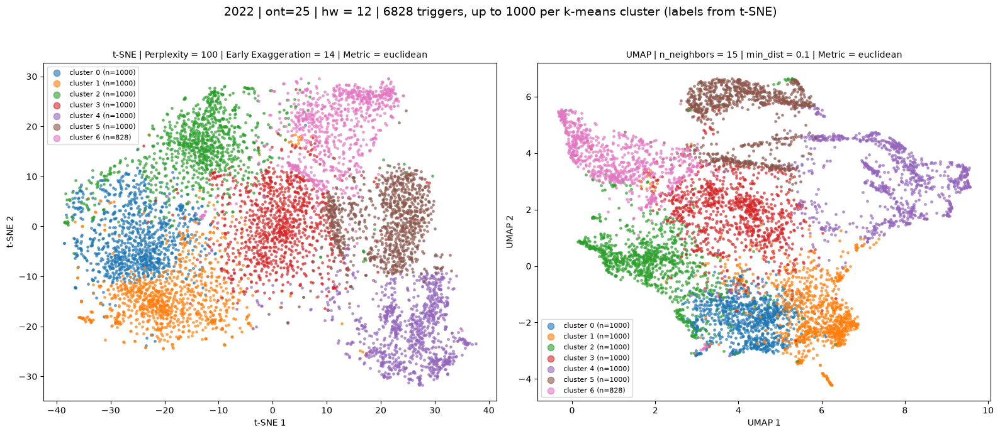

In [11]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run_subset(year, ont, hw)